# AquaTrace: Estimation Model · real river data → Phi's website

**Goal:** show one full flow: cheap sensor readings in → **screening estimate** of a medicine out → checked against the **lab result (= ground truth)**. Then export the model so Phi's website runs the same thing.

**Data:** `AquaTrace_Master_Data.xlsx`, sheet `paired_samples`: **28,046 real US river samples** (US Water Quality Portal, USGS/EPA) where a lab measured the medicine **and** field sensors were read at the same site on the same day. Penang has no such paired data yet, so we learn the method on US rivers first.

**Three phases, split by river site (no site appears in two sets):**
| Set | Share of sites | Used for |
|---|---|---|
| **Training set** | 60% | Phase 1: fit candidate models |
| **Validation set** | 20% | Phase 2: choose the best settings and the flag line |
| **Testing set** | 20% | Phase 3: one final exam on rivers the model never saw |

After Phase 2, the chosen model is refit on training + validation sites (more data, same settings) and then scored **once** on the testing set.

**The flow (pipeline):**
| Step | What happens |
|---|---|
| 0 | Get the data file (Google Drive or upload) |
| 1 | Clean impossible readings |
| 2 | Choose sensors per medicine |
| 3 | Define "high" + split sites into training / validation / testing |
| 4 | Phase 1 + 2: train candidates, choose on validation; Phase 3: final test ⭐ |
| 4b | Which algorithm? 7 compared: logistic regression, decision tree, random forest, SVM, KNN, naive Bayes, gradient boosting ⭐ |
| 4c | **Fewer false alarms:** two-step model (detected? then high?), season, red and amber alert lines ⭐ |
| 5 | Full metric report: confusion matrix, precision, recall, F1, accuracy, ROC-AUC, AP, **mAP** ⭐ |
| 5b | Evaluation dashboard: confusion matrix + accuracy / precision / recall / F1 gauges against random ⭐ |
| 6 | Precision-recall curves + AP check (same formula as the object-detection guide) |
| 7 | Stricter "high" lines: **mAP@P50:P90** (our version of mAP@50:95) |
| 8 | Level model metrics: R², RMSE, MAE, within 2× |
| 9 | Explain: which sensor matters |
| 10 | **One full estimation flow, one sample** ⭐ |
| 11 | Cross-check every testing-set lab result |
| 12 | Screen new readings, incl. Penang-style examples |
| 13 | Export the 4 files for the website |

**Two models per medicine:**
1. **Screening model:** "Is this water likely HIGH for this medicine?" → a probability (our **confidence score**). This is the strong one. It gives a **red** alert (send this sample to the lab) or an **amber** alert (watch this spot).
2. **Level model:** "If present, roughly how much?" → µg/L. Weaker, so it always comes with a wide range.

> **Key message for judges:** sensors cannot *identify* a medicine. They tell us **where and when to send a sample to the lab**. HPLC / LC-MS stays the reference.

**How to run:** `Runtime → Run all`. Step 0 will ask for the data file the first time.

### How object-detection metrics map to our model
Object detection (e.g. YOLO, measured with mAP@50) finds **boxes** in **images**. Our model finds **water samples likely high in a medicine**. Every metric carries over except IoU, because we do not draw boxes: each sample is simply high or not according to the lab.

| Object detection | AquaTrace |
|---|---|
| One image | One water sample (sensor readings at one site on one day) |
| Class (cat, dog, raccoon) | Medicine (5 models) |
| Bounding box + IoU ≥ 0.5 to count a match | **Not needed:** the lab result says directly whether a sample is high |
| Confidence score | P(high), the screening probability |
| True positive (TP) | Flagged, and the lab says high |
| False positive (FP) | Flagged, but the lab says low (false alarm) |
| False negative (FN) | Not flagged, but the lab says high (missed) |
| True negative (TN) | Not flagged, and the lab says low |
| Precision = TP / (TP + FP) | Of the samples we send to the lab, the share that are truly high (hit rate) |
| Recall = TP / (TP + FN) | Of the truly high samples, the share we flag (caught) |
| F1 = 2PR / (P + R) | Balance of precision and recall |
| AP = area under the precision-recall curve | Same, per medicine |
| mAP@50 = mean AP over classes at IoU 0.5 | **mAP = mean AP over the 5 medicines** at our "high" line |
| mAP@50:95 = mean over stricter IoU lines | **mAP@P50:P90 = mean over stricter "high" lines** (50th to 90th percentile of detections) |

One extra metric that object detection lacks: **AP depends on how common "high" is**. A random guess scores AP = the share of high samples, so we always show that baseline next to AP.

## Step 0: Setup + get the data

The cell looks for `AquaTrace_Master_Data.xlsx` in this order:
1. Already uploaded to this Colab session
2. **Google Drive** (recommended): put the file anywhere in *My Drive*. Colab asks once for permission to read your Drive.
3. **Upload** from your computer: a *Choose files* button appears under the cell.

Set `USE_DRIVE = False` if you prefer to just upload.

In [1]:
import os, sys, glob, json, shutil, datetime as dt, warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestRegressor, RandomForestClassifier
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import (r2_score, roc_auc_score, average_precision_score, precision_recall_curve,
                             mean_squared_error, mean_absolute_error)
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr, pearsonr
pd.set_option('display.width', 220); pd.set_option('display.max_columns', 40)

FILE = 'AquaTrace_Master_Data.xlsx'
USE_DRIVE = True
IN_COLAB = 'google.colab' in sys.modules

def find_data():
    if os.path.exists(FILE):                       # 1. already here
        return FILE
    if IN_COLAB and USE_DRIVE:                     # 2. Google Drive
        from google.colab import drive
        drive.mount('/content/drive')
        for pat in ['/content/drive/MyDrive/' + FILE, '/content/drive/MyDrive/*/' + FILE, '/content/drive/MyDrive/**/' + FILE]:
            hits = glob.glob(pat, recursive=True)
            if hits:
                return hits[0]
        print('Not found in Google Drive.')
    if IN_COLAB:                                   # 3. upload
        from google.colab import files
        print('Please choose', FILE, 'from your computer:')
        up = files.upload()
        return next(n for n in up if n.endswith('.xlsx'))
    raise FileNotFoundError(FILE + ' not found next to this notebook')

path = find_data()
raw = pd.read_excel(path, sheet_name='paired_samples')
df = raw.rename(columns={'conductivity_uScm':'conductivity', 'turbidity_NTU':'turbidity', 'temp_C':'temp', 'do_mgL':'do'})
df['date'] = df['date'].astype(str).str[:10]
print('Data file:', path)
print(f'{len(df):,} paired samples | {df.site.nunique():,} river sites | {df.date.min()} to {df.date.max()}')
df[['site','date','ph','temp','conductivity','turbidity','do','Carbamazepine_ngL','Sulfamethoxazole_ngL']].head()

Data file: AquaTrace_Master_Data.xlsx
28,046 paired samples | 5,983 river sites | 1999-03-09 to 2025-10-20


,site,date,ph,temp,conductivity,turbidity,do,Carbamazepine_ngL,Sulfamethoxazole_ngL
0,USGS-14204530,2002-07-25,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,USGS-390127094365800,2002-11-07,7.50,7.1,392.0,13.85,NaN,NaN,NaN
2,USGS-390127094365800,2003-07-15,7.95,27.9,499.0,4.50,NaN,NaN,NaN
3,USGS-390127094365800,2007-06-28,7.90,22.3,330.0,94.00,NaN,NaN,NaN
4,USGS-390127094365800,2007-08-16,8.20,28.6,785.0,1.60,NaN,NaN,NaN


## Step 1: Clean
Remove impossible readings (typing or unit errors). Example: pH 14.5 or a temperature of 300 °C cannot be real river water.

**Not detected:** when the lab sees nothing, the value is empty and we keep the **detection limit (LOD)**. Later it is stored as **LOD ÷ 2**, the same rule as the website.

In [2]:
rng = {'ph':(3,11), 'do':(0,20), 'conductivity':(1,60000), 'temp':(-1,40), 'turbidity':(0,4000)}
for c,(lo,hi) in rng.items():
    bad = (df[c] < lo) | (df[c] > hi)
    df.loc[bad, c] = np.nan
    print(f'{c:13s} removed {bad.sum():4d} impossible values')
df[list(rng)].describe().round(2)

ph            removed    3 impossible values
do            removed    3 impossible values
conductivity  removed   19 impossible values
temp          removed    8 impossible values
turbidity     removed   14 impossible values


,ph,do,conductivity,temp,turbidity
count,23700.00,13991.00,20166.00,23179.00,14015.00
mean,7.35,7.04,2132.50,19.06,32.17
std,0.84,2.77,7770.83,7.29,128.66
min,3.00,0.01,2.42,-0.80,0.00
25%,7.00,5.20,140.00,14.60,2.70
50%,7.49,7.10,337.50,20.40,5.80
75%,7.91,8.73,689.50,24.50,16.00
max,10.20,19.77,59101.00,39.90,3240.00


## Step 2: Choose sensors per medicine
The model can only estimate when **every** input sensor has a value. Asking for all 5 sensors throws away most samples, so each medicine uses the combination with the best **coverage × accuracy**. (Full comparison: sheet `analysis_sensor_subsets` in the workbook.)

| Medicine | Sensors | Why |
|---|---|---|
| Carbamazepine, atenolol, sulfamethoxazole | pH + temperature + conductivity | conductivity tracks **treated sewage effluent** |
| Paracetamol | pH + turbidity + temperature + **DO** | fresh sewage uses up oxygen |
| Caffeine | pH + turbidity + conductivity | **raw-sewage marker** |

UV254 and ORP are measured on the boat, but almost no US river sample has them together with a medicine result, so they cannot be trained here. They come in when Penang data exists.

In [3]:
COMPS = [  # website id, medicine in data, display name, sensors
    ('CBZ-US', 'Carbamazepine',    'Carbamazepine (US model)',    ['ph','temp','conductivity']),
    ('PCM-US', 'Acetaminophen',    'Paracetamol (US model)',      ['ph','turbidity','temp','do']),
    ('ATL-US', 'Atenolol',         'Atenolol (US model)',         ['ph','temp','conductivity']),
    ('SMX-US', 'Sulfamethoxazole', 'Sulfamethoxazole (US model)', ['ph','temp','conductivity']),
    ('CAF-US', 'Caffeine',         'Caffeine (US model)',         ['ph','turbidity','conductivity']),
]
INFO = {'Carbamazepine':('Anticonvulsant','298-46-4',2.45), 'Acetaminophen':('Analgesic / antipyretic','103-90-2',0.46),
        'Atenolol':('Beta-blocker','29122-68-7',0.16), 'Sulfamethoxazole':('Antibiotic (sulfonamide)','723-46-6',0.89),
        'Caffeine':('Stimulant, raw-sewage marker','58-08-2',-0.07)}
ALLF = ['ph','turbidity','temp','conductivity','do']
LABEL = {'ph':'pH', 'temp':'Temp (°C)', 'conductivity':'Conductivity (µS/cm)', 'turbidity':'Turbidity (NTU)', 'do':'DO (mg/L)'}
UNIT, FAC = 'µg/L', 1e-3   # website shows µg/L (ng/L × 0.001)
# fixed parts of the models (60 trees keeps the website file small)
CLF_BASE = dict(n_estimators=60, max_features=0.6, class_weight='balanced', random_state=0, n_jobs=-1)
REG_BASE = dict(n_estimators=60, max_features=0.6, random_state=0, n_jobs=-1)
# candidate settings tried in Phase 1 and judged in Phase 2
GRID_CLF = [dict(max_depth=d, min_samples_leaf=l) for d in (4, 6, 8, 12) for l in (5, 10, 25)]
GRID_REG = [dict(max_depth=d, min_samples_leaf=l) for d in (4, 6, 8, 12) for l in (4, 8, 16)]
print(f'5 medicines · {len(GRID_CLF)} screening candidates · {len(GRID_REG)} level candidates ✅')

5 medicines · 12 screening candidates · 12 level candidates ✅


## Step 3: Define "high" + split sites into training / validation / testing
- **High** = above the median of all US detections for that medicine (e.g. carbamazepine 11.9 ng/L). It is a **screening level**, not a safety limit.
- Not detected counts as "low" only if the lab could see down to that level. Otherwise we do not know, so the sample is dropped.
- **Split by river site**, so no river appears in two sets:
    - **Testing set:** 20% of sites, held back first (`GroupShuffleSplit`, seed 42). Nothing about them is used until Phase 3.
    - **Validation set:** 25% of the remaining sites (= 20% of all), seed 7.
    - **Training set:** the other 60%.

- **Detected** = the lab found the medicine at all. Most samples are "not detected", which is why a one-step model raises many false alarms (Step 4c).
- **Season** = the month of the sampling date, written as two numbers on a circle (so December sits next to January). One candidate model may use it (Step 4).

Testing on unseen sites is like testing a student on a river they have never visited.

In [4]:
def export_tree(est, clf):
    # website tree format: [feature, threshold, left, right] for a split, [value] for a leaf (x <= threshold goes left)
    t = est.tree_; nodes = []
    for i in range(t.node_count):
        if t.children_left[i] == -1:
            v = t.value[i][0]; nodes.append([round(float(v[1]/v.sum()) if clf else float(v[0]), 6)])
        else:
            nodes.append([int(t.feature[i]), float(t.threshold[i]), int(t.children_left[i]), int(t.children_right[i])])
    return nodes

def voc_ap(y, p):
    # AP the way the object-detection guide computes it (VOC style): make precision non-increasing, then sum (R_i - R_i-1) x P_i
    prec, rec, _ = precision_recall_curve(y, p)
    prec, rec = prec[::-1].copy(), rec[::-1].copy()          # recall now goes 0 -> 1
    for i in range(len(prec) - 2, -1, -1):
        prec[i] = max(prec[i], prec[i + 1])
    return float(np.sum(np.diff(rec) * prec[1:]))

def cls_metrics(y, p, thr):
    y = np.asarray(y).astype(bool); f = np.asarray(p) >= thr
    tp, fp, fn, tn = int((f & y).sum()), int((f & ~y).sum()), int((~f & y).sum()), int((~f & ~y).sum())
    prec = tp / (tp + fp) if tp + fp else np.nan; rec = tp / (tp + fn) if tp + fn else np.nan
    f1 = 2 * prec * rec / (prec + rec) if (tp and prec + rec) else 0.0
    base = y.mean()
    return {'n': len(y), 'high': int(y.sum()), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn,
            'precision': prec, 'recall': rec, 'f1': f1, 'accuracy': (tp + tn) / len(y),
            'roc_auc': roc_auc_score(y, p), 'ap': average_precision_score(y, p), 'ap_voc': voc_ap(y, p),
            'base_rate': base, 'lift': prec / base if base else np.nan, 'flagged_share': f.mean()}

def web_screen(m):   # the keys the website reads
    return {'auc': m['roc_auc'], 'flagged_share': m['flagged_share'], 'hit_rate': m['precision'], 'base_rate': m['base_rate'],
            'caught_share': m['recall'], 'agree': m['accuracy'], 'precision': m['precision'], 'recall': m['recall'],
            'f1': m['f1'], 'ap': m['ap'], 'tp': m['TP'], 'fp': m['FP'], 'fn': m['FN'], 'tn': m['TN']}

def reg_metrics(y, yhat):
    return {'n': len(y), 'r2': r2_score(y, yhat), 'rmse': float(np.sqrt(mean_squared_error(y, yhat))),
            'mae': float(mean_absolute_error(y, yhat)), 'within2x': float(np.mean(np.abs(yhat - y) <= np.log10(2)))}

# season: month on a circle, rounded to 6 decimals; the website and the online ML API use this same table
SEASON = {m: (round(float(np.sin(2 * np.pi * m / 12)), 6), round(float(np.cos(2 * np.pi * m / 12)), 6)) for m in range(1, 13)}
SF = ['m_sin', 'm_cos']
month = pd.to_datetime(df['date'], errors='coerce').dt.month
df['m_sin'] = month.map(lambda m: SEASON[int(m)][0] if m == m else np.nan)
df['m_cos'] = month.map(lambda m: SEASON[int(m)][1] if m == m else np.nan)

gss_test = GroupShuffleSplit(n_splits=1, test_size=0.20, random_state=42)   # testing set: 20% of sites
gss_val  = GroupShuffleSplit(n_splits=1, test_size=0.25, random_state=7)    # validation: 25% of the rest = 20% of all
pkg = {'format':'aquatrace-model-package/3', 'created': dt.datetime.now(dt.timezone.utc).strftime('%Y-%m-%dT%H:%M:%SZ'),
       'source':'US Water Quality Portal (USGS/EPA), river sites 1999-2025: lab results paired with same-site, same-day field readings',
       'note':"Screening model = probability the medicine is above the 'high' level (median of US detections). Level model = expected concentration when present. Sites split 60/20/20 into training, validation and testing; settings chosen on validation, final model refit on training + validation, scored once on testing.",
       'models':{}, 'compounds':[],
       'season_table':{'m_sin':[SEASON[m][0] for m in range(1, 13)], 'm_cos':[SEASON[m][1] for m in range(1, 13)]}}
report, cross_rows, imps, fitted, METRICS, LEVELM, SPLITS, CHOSEN = [], [], {}, {}, {}, {}, [], []
METRICS_AMBER, BEFORE, CANDS = {}, {}, []

DATA = {}
for cid, name, disp, feats in COMPS:
    v, lim = f'{name}_ngL', f'{name}_lim_ngL'
    T = float(np.nanmedian(df[v]))
    d = df[df[feats].notna().all(axis=1) & (df[v].notna() | df[lim].notna())].copy()
    d = d[d[v].notna() | (d[lim] <= T)].copy()
    d['below'] = d[v].isna(); d['conc_ng'] = np.where(d.below, d[lim]/2, d[v]); d['high'] = (d[v] >= T).fillna(False).astype(int)
    d['det'] = (~d.below).astype(int)
    dev_i, te_i = next(gss_test.split(d, groups=d.site)); dev, te = d.iloc[dev_i], d.iloc[te_i]
    tr_i, va_i = next(gss_val.split(dev, groups=dev.site)); tr, va = dev.iloc[tr_i], dev.iloc[va_i]
    assert not (set(tr.site) & set(va.site)) and not (set(tr.site) & set(te.site)) and not (set(va.site) & set(te.site))
    DATA[cid] = dict(name=name, disp=disp, feats=feats, v=v, lim=lim, T=T, dev=dev, tr=tr, va=va, te=te)
    for nm, part in [('Training', tr), ('Validation', va), ('Testing', te)]:
        SPLITS.append({'medicine': cid, 'set': nm, 'samples': len(part), 'sites': part.site.nunique(), 'detected': int(part.det.sum()),
                       'high': int(part.high.sum()), 'share detected': f'{part.det.mean():.0%}', 'share high': f'{part.high.mean():.0%}'})
S = pd.DataFrame(SPLITS).set_index(['medicine', 'set']); S

samples  sites  detected  high share detected share high
medicine set                                                                 
CBZ-US   Training       6637   1728       827   308            12%         5%
         Validation     2310    577       367   155            16%         7%
         Testing        2286    577       331   146            14%         6%
PCM-US   Training       4576   1161       189   105             4%         2%
         Validation     1652    387        61    31             4%         2%
         Testing        1647    387        88    47             5%         3%
ATL-US   Training        812    333        65    33             8%         4%
         Validation      247    111        34    23            14%         9%
         Testing         253    111        24    18             9%         7%
SMX-US   Training       1063    417       244   152            23%        14%
         Validation      388    139        90    69            23%        18%
         Testing         382    140       131    84            34%        22%
CAF-US   Training       2355    723       509   331            22%        14%
         Validation      785    241       210   168            27%        21%
         Testing         680    241       199   154            29%        23%

## Step 4: Phase 1 + 2 + 3: train, choose, test ⭐
For each medicine, three kinds of screening model compete, all random forests:

| Kind | How it scores a reading |
|---|---|
| **One-step** | One forest: P(high) directly (the first version of this notebook) |
| **Two-step** | Forest 1: P(detected at all). Forest 2, trained only on detected samples: P(high, if detected). Score = the two multiplied |
| **Two-step + season** | The same, with the month (season) as an extra input |

1. **Phase 1, training set:** fit every kind with 12 candidate settings each (tree depth 4–12 × minimum leaf size 5–25).
2. **Phase 2, validation set:** keep the kind and settings with the highest **AP** on validation sites. Then set two **alert lines**:
    - 🔴 **Red** = the riskiest 5% of validation readings: "send this sample to the lab".
    - 🟠 **Amber** = the next 5% (riskiest 5–10%): "watch this spot, take a second reading"; no lab test yet.
3. Refit the chosen model on training + validation sites.
4. **Phase 3, testing set:** score once. These are the numbers we report and the website shows. **"Flagged" means a red alert.**

The two-step idea and the season input come from Kekić et al. (2026), *Antibiotics* 15, 920: model "is it there?" apart from "how much?". The level model goes through the same three phases, chosen by R² on validation. Takes about 3 minutes.

In [5]:
KINDS = ['one-step', 'two-step', 'two-step + season']

class Screen:
    # screening model. one-step: P(high) directly. two-step: P(detected) x P(high | detected).
    def __init__(self, kind, cols, g1, g2=None):
        self.kind, self.cols, self.g1, self.g2 = kind, cols, g1, g2
    def fit(self, part):
        X = part[self.cols].values
        if self.kind == 'one-step':
            self.m1 = RandomForestClassifier(**self.g1, **CLF_BASE).fit(X, part.high.values)
        else:
            dd = part[part.det == 1]
            self.m1 = RandomForestClassifier(**self.g1, **CLF_BASE).fit(X, part.det.values)
            self.m2 = RandomForestClassifier(**self.g2, **CLF_BASE).fit(dd[self.cols].values, dd.high.values)
        return self
    def score(self, part):
        X = part[self.cols].values; p = self.m1.predict_proba(X)[:, 1]
        return p if self.kind == 'one-step' else p * self.m2.predict_proba(X)[:, 1]

def best_rf(Xtr, ytr, Xva, yva):
    # Phase 1 + 2 for one forest: fit each candidate setting on training sites, keep the best AP on validation sites
    return max(((average_precision_score(yva, RandomForestClassifier(**g, **CLF_BASE).fit(Xtr, ytr).predict_proba(Xva)[:, 1]), g)
                for g in GRID_CLF), key=lambda c: c[0])[1]

def candidate(kind, feats, tr, va):
    cols = feats + SF if kind.endswith('season') else feats
    if kind == 'one-step':
        s_ = Screen(kind, cols, best_rf(tr[cols].values, tr.high.values, va[cols].values, va.high.values))
    else:
        trd, vad = tr[tr.det == 1], va[va.det == 1]
        s_ = Screen(kind, cols, best_rf(tr[cols].values, tr.det.values, va[cols].values, va.det.values),
                    best_rf(trd[cols].values, trd.high.values, vad[cols].values, vad.high.values))
    pva_ = s_.fit(tr).score(va)
    return average_precision_score(va.high, pva_), s_, pva_

def perm_importance(scr, te, feats, reps=8):
    # shuffle one input (season: both month numbers together) and see how much the testing-set ROC-AUC drops
    groups = {f: [f] for f in feats}
    if scr.cols != feats: groups['season'] = SF
    rng = np.random.default_rng(0); base = roc_auc_score(te.high, scr.score(te)); out = {}
    for g, cs in groups.items():
        drops = []
        for _ in range(reps):
            t2 = te.copy(); t2[cs] = t2[cs].values[rng.permutation(len(t2))]
            drops.append(base - roc_auc_score(t2.high, scr.score(t2)))
        out[g] = max(float(np.mean(drops)), 0.0)
    tot = sum(out.values()) or 1.0
    return {k: v / tot for k, v in out.items()}

for cid, *_ in COMPS:
    D = DATA[cid]; name, disp, feats, v, lim, T = D['name'], D['disp'], D['feats'], D['v'], D['lim'], D['T']
    dev, tr, va, te = D['dev'], D['tr'], D['va'], D['te']
    # ---- screening model: Phase 1 (fit on training) + Phase 2 (judge on validation), three kinds compete
    cands = {k: candidate(k, feats, tr, va) for k in KINDS}
    kind = max(KINDS, key=lambda k: cands[k][0])
    ap_val, scr_tr, pva = cands[kind]
    red, amber = float(np.quantile(pva, 0.95)), float(np.quantile(pva, 0.90))   # red: riskiest 5% · amber: riskiest 5-10%
    ptr = scr_tr.score(tr)
    # refit on training + validation, then Phase 3: one final test
    scr = Screen(scr_tr.kind, scr_tr.cols, scr_tr.g1, scr_tr.g2).fit(dev)
    pte = scr.score(te)
    M = {'Training': cls_metrics(tr.high, ptr, red), 'Validation': cls_metrics(va.high, pva, red), 'Testing': cls_metrics(te.high, pte, red)}
    MA = {'Training': cls_metrics(tr.high, ptr, amber), 'Validation': cls_metrics(va.high, pva, amber), 'Testing': cls_metrics(te.high, pte, amber)}
    METRICS[cid], METRICS_AMBER[cid] = M, MA
    # the first version, for the before/after table in Step 4c: one-step forest, one flag line at the riskiest 10%
    _, one_tr, one_pva = cands['one-step']
    one_pte = Screen('one-step', feats, one_tr.g1).fit(dev).score(te); one_line = float(np.quantile(one_pva, 0.90))
    BEFORE[cid] = dict(cls_metrics(te.high, one_pte, one_line), fp_not_detected=int(((one_pte >= one_line) & (te.high.values == 0) & (te.det.values == 0)).sum()))
    CANDS.append({'medicine': cid, **{f'{k}': round(cands[k][0], 3) for k in KINDS}, 'chosen': kind,
                  'red line': round(red, 3), 'amber line': round(amber, 3)})
    # ---- level model: same three phases, judged by R² (log10 ng/L), detected samples only
    trd, vad, ted, devd = tr[~tr.below], va[~va.below], te[~te.below], dev[~dev.below]
    ytr, yva, yt, ydev = (np.log10(x.conc_ng.values) for x in (trd, vad, ted, devd))
    candsR = []
    for g in GRID_REG:
        r_ = RandomForestRegressor(**g, **REG_BASE).fit(trd[feats].values, ytr)
        pvl_ = r_.predict(vad[feats].values); candsR.append((r2_score(yva, pvl_), g, r_, pvl_))
    _, gR, reg_tr, pvl = max(candsR, key=lambda c: c[0])
    reg = RandomForestRegressor(**gR, **REG_BASE).fit(devd[feats].values, ydev); tel = reg.predict(ted[feats].values)
    L = {'Training': reg_metrics(ytr, reg_tr.predict(trd[feats].values)), 'Validation': reg_metrics(yva, pvl), 'Testing': reg_metrics(yt, tel)}
    LEVELM[cid] = L
    lvl = {'r2_log_cv': L['Validation']['r2'], 'within2x_cv': L['Validation']['within2x'], 'rmse_log_cv': L['Validation']['rmse'],
           'r2_log_holdout': L['Testing']['r2'], 'within2x_holdout': L['Testing']['within2x'], 'rmse_log_holdout': L['Testing']['rmse'],
           'mae_log_holdout': L['Testing']['mae']}
    sset = lambda g: f"depth {g['max_depth']}, leaf {g['min_samples_leaf']}"
    CHOSEN.append({'medicine': cid, 'screening model': kind, 'settings': sset(scr.g1) + (f" · {sset(scr.g2)}" if scr.g2 else ''),
                   'validation AP': round(ap_val, 3), 'red line P ≥': round(red, 3), 'amber line P ≥': round(amber, 3),
                   'level settings': sset(gR), 'validation R² (level)': round(L['Validation']['r2'], 3)})
    # ---- explain + package for the website
    imp = perm_importance(scr, te, feats); imps[disp] = imp
    fitted[cid] = {'screen':scr, 'reg':reg, 'te':te, 'va':va, 'pte':pte, 'pva':pva, 'tel':tel, 'yt':yt, 'T':T, 'one_pte':one_pte, 'one_line':one_line}
    sub = np.random.default_rng(0).choice(len(vad), size=min(400, len(vad)), replace=False)
    trees = ({'clf_trees':[export_tree(e, True) for e in scr.m1.estimators_]} if scr.kind == 'one-step' else
             {'det_trees':[export_tree(e, True) for e in scr.m1.estimators_], 'cond_trees':[export_tree(e, True) for e in scr.m2.estimators_]})
    pkg['models'][cid] = {'name':disp, 'unit':UNIT, 'ng_to_unit':FAC, 'feats':feats, 'threshold':T*FAC, 'threshold_ngL':round(T,2),
        'kind':'one-step' if scr.kind == 'one-step' else 'two-step', 'season':scr.cols != feats,
        'p_threshold':red, 'p_amber':amber, 'alert_rule':'red = riskiest 5% of validation readings (send to lab); amber = riskiest 5-10% (watch)',
        'n':int(len(dev)), 'n_detected':int(len(devd)), 'n_sites':int(dev.site.nunique()), 'n_holdout':int(len(te)), 'n_holdout_sites':int(te.site.nunique()),
        'split':{'training':{'samples':int(len(tr)),'sites':int(tr.site.nunique())}, 'validation':{'samples':int(len(va)),'sites':int(va.site.nunique())},
                 'testing':{'samples':int(len(te)),'sites':int(te.site.nunique())}},
        'chosen':{'screening':{'kind':kind, 'forest_1':scr.g1, 'forest_2':scr.g2}, 'level':gR},
        'screen_cv':{k:round(float(x),3) for k,x in web_screen(M['Validation']).items()},
        'screen_holdout':{k:round(float(x),3) for k,x in web_screen(M['Testing']).items()},
        'screen_train':{k:round(float(x),3) for k,x in web_screen(M['Training']).items()},
        'screen_holdout_amber':{k:round(float(x),3) for k,x in web_screen(MA['Testing']).items()},
        'level':{k:round(float(x),3) for k,x in lvl.items()}, 'ranges':[[float(dev[f].min()), float(dev[f].max())] for f in feats],
        'importance':sorted([{'f':f,'v':round(float(x),4)} for f,x in imp.items()], key=lambda r:-r['v']),
        'corr':[{'f':f,'r':round(float(pearsonr(devd[f], ydev)[0]),3),'rho':round(float(spearmanr(devd[f], devd.conc_ng)[0]),3)} for f in feats],
        'oof':[{'y':float(10**yva[i]*FAC),'yhat':float(10**pvl[i]*FAC),'id':f'{vad.site.iloc[i]} {vad.date.iloc[i]}','below':False} for i in sub],
        **trees, 'reg_trees':[export_tree(e, False) for e in reg.estimators_]}
    cls_, cas, kow = INFO[name]
    pkg['compounds'].append({'id':cid, 'name':disp, 'cls':cls_, 'cas':cas, 'kow':kow, 'unit':UNIT, 'level':round(T*FAC,5), 'pnec':None, 'bg':0, 'rt':None,
        'method':'US labs (mostly LC-MS/MS), Water Quality Portal', 'src':f'US-trained model package. Level = median of US detections ({T:.1f} ng/L); screening only, not a safety limit.'})
    t = M['Testing']
    report.append({'medicine':disp, 'model':kind, 'sensors':' + '.join(feats), 'high above (ng/L)':round(T,1), 'training / validation / testing samples':f'{len(tr)} / {len(va)} / {len(te)}',
                   'ROC-AUC (test)':round(t['roc_auc'],3), 'AP (test)':round(t['ap'],3), 'random AP':round(t['base_rate'],3),
                   'precision (test)':f"{t['precision']:.0%}", 'recall (test)':f"{t['recall']:.0%}", 'F1 (test)':round(t['f1'],2),
                   'lift':round(t['lift'],1), 'level R² (log, test)':round(L['Testing']['r2'],2), 'level within 2× (test)':f"{L['Testing']['within2x']:.0%}"})
    for i,(_,r) in enumerate(te.sort_values('date').iterrows()):
        row = {'sample_id':f'{cid}-{i+1:03d}', 'timestamp':f'{r.date}T12:00:00Z', 'lat':r.lat, 'lon':r.lon, 'compound':cid,
               'concentration':'<LOD' if r.below else f'{r.conc_ng*FAC:.6g}', 'unit':UNIT, 'lod':f'{r[lim]*FAC:.6g}' if r.below else '',
               'method':'US lab, Water Quality Portal', 'notes':f'testing-set site {r.site}'}
        for f in ALLF: row[f] = '' if pd.isna(r[f]) else round(float(r[f]),4)
        cross_rows.append(row)
    print(f"{disp:30s} done · {kind:18s} · test ROC-AUC {t['roc_auc']:.2f} · test AP {t['ap']:.2f} (random {t['base_rate']:.2f})")
print()
display(pd.DataFrame(CHOSEN).set_index('medicine'))
R = pd.DataFrame(report).set_index('medicine'); R

Carbamazepine (US model)       done · two-step + season  · test ROC-AUC 0.76 · test AP 0.25 (random 0.06)


Paracetamol (US model)         done · one-step           · test ROC-AUC 0.71 · test AP 0.09 (random 0.03)


Atenolol (US model)            done · two-step           · test ROC-AUC 0.92 · test AP 0.74 (random 0.07)


Sulfamethoxazole (US model)    done · two-step + season  · test ROC-AUC 0.87 · test AP 0.68 (random 0.22)


Caffeine (US model)            done · two-step + season  · test ROC-AUC 0.73 · test AP 0.47 (random 0.23)



,screening model,settings,validation AP,red line P ≥,amber line P ≥,level settings,validation R² (level)
medicine,,,,,,,
CBZ-US,two-step + season,"depth 8, leaf 25 · depth 12, leaf 5",0.276,0.511,0.388,"depth 12, leaf 16",0.103
PCM-US,one-step,"depth 4, leaf 10",0.053,0.645,0.580,"depth 8, leaf 4",0.130
ATL-US,two-step,"depth 6, leaf 5 · depth 4, leaf 10",0.667,0.453,0.419,"depth 6, leaf 4",0.316
SMX-US,two-step + season,"depth 4, leaf 5 · depth 8, leaf 10",0.504,0.625,0.556,"depth 8, leaf 4",0.168
CAF-US,two-step + season,"depth 12, leaf 10 · depth 4, leaf 5",0.604,0.518,0.433,"depth 6, leaf 4",0.199


,model,sensors,high above (ng/L),training / validation / testing samples,ROC-AUC (test),AP (test),random AP,precision (test),recall (test),F1 (test),lift,"level R² (log, test)",level within 2× (test)
medicine,,,,,,,,,,,,,
Carbamazepine (US model),two-step + season,ph + temp + conductivity,11.9,6637 / 2310 / 2286,0.755,0.248,0.064,41%,34%,0.37,6.4,0.14,40%
Paracetamol (US model),one-step,ph + turbidity + temp + do,42.0,4576 / 1652 / 1647,0.710,0.090,0.029,8%,28%,0.12,2.8,0.04,43%
Atenolol (US model),two-step,ph + temp + conductivity,30.8,812 / 247 / 253,0.923,0.741,0.071,47%,78%,0.58,6.6,0.25,62%
Sulfamethoxazole (US model),two-step + season,ph + temp + conductivity,38.4,1063 / 388 / 382,0.868,0.680,0.220,89%,20%,0.33,4.1,0.52,61%
Caffeine (US model),two-step + season,ph + turbidity + conductivity,100.0,2355 / 785 / 680,0.727,0.470,0.226,66%,15%,0.24,2.9,-0.01,44%


**How to read it:**
- **ROC-AUC:** 0.5 = coin flip, 1.0 = perfect ranking of high above low.
- **AP:** area under the precision-recall curve. Compare it with **random AP** (the share of high samples): AP far above random = the model ranks high samples first.
- **Precision (test)** = of the red-alert readings, how many were truly high. **Lift** = precision ÷ random. That is the **lab-cost saving**: the same lab budget finds lift× more polluted samples.
- **Level model** is weak (R² well below 1). So the website leads with the screening flag and shows the level with a wide range.

## Step 4b: Which algorithm? 7 compared ⭐
Step 4 uses a **random forest**. Is that the best choice? Here every common algorithm gets the **same chance**:

| Algorithm | Idea in one line |
|---|---|
| Logistic regression | A weighted sum of the sensors → probability (we also allow squared terms) |
| Decision tree | One tree of yes/no questions |
| Random forest | 60 trees on random parts of the data, averaged (Step 4) |
| SVM (RBF kernel) | Finds a curved boundary between high and low samples |
| K-nearest neighbours | Looks at the k most similar past samples |
| Naive Bayes | Treats each sensor as independent evidence |
| Gradient boosting | Trees added one by one, each fixing the previous ones' errors (like XGBoost) |
| Always says LOW (dummy) | Never flags anything: the floor every model must beat |

**Same rules for all:** same sensors, same river sites, same three phases, same flag line (riskiest 10% of validation readings). Each algorithm tries its own candidate settings. Logistic regression, SVM, KNN and naive Bayes get conductivity and turbidity on a log scale and standardised inputs, because they are sensitive to scale; trees do not need it.

**Choose by mAP, not accuracy.** Most water is low, so the dummy that never flags anything has the **highest accuracy** and finds **nothing**. AP / mAP measures what we need: are the truly high samples at the top of the list?

**Two checks:**
1. **Single split:** Phase 1 on training sites, choose on the validation sites (as in Step 4), test once.
2. **5-fold cross-validation (more reliable):** training + validation sites are cut into 5 groups by site; each group takes a turn as the validation set. The **testing set is never touched**. The spread over the 5 folds shows how much of a difference is just luck.

Testing-set numbers are shown for information only: **choosing the algorithm on the testing set would be cheating**, because then the test is no longer unseen.

`RUN_CV = True` takes about 4 minutes on Colab. Set it to `False` to run only the single split (about 1 minute).

In [6]:
import time
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import FunctionTransformer, StandardScaler, PolynomialFeatures
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import GroupKFold
RUN_CV = True

def scaled(F):
    # conductivity and turbidity are very skewed: log scale, then standardise (needed by linear and distance-based models)
    idx = [i for i, f in enumerate(F) if f in ('conductivity', 'turbidity')]
    def logx(X):
        X = np.array(X, dtype=float, copy=True); X[:, idx] = np.log10(X[:, idx] + 1); return X
    return [FunctionTransformer(logx), StandardScaler()]

ALGOS = {   # name: (how to build it, candidate settings tried in Phase 1)
    'Logistic regression': (lambda F, C, deg: make_pipeline(*scaled(F), PolynomialFeatures(deg, include_bias=False),
                                                            LogisticRegression(C=C, class_weight='balanced', max_iter=2000)),
                            [dict(C=C, deg=d) for d in (1, 2) for C in (0.01, 0.1, 1, 10)]),
    'Decision tree': (lambda F, depth, leaf: DecisionTreeClassifier(max_depth=depth, min_samples_leaf=leaf, class_weight='balanced', random_state=0),
                      [dict(depth=d, leaf=l) for d in (3, 4, 6, 8, 12) for l in (5, 25, 100)]),
    'Random forest': (lambda F, max_depth, min_samples_leaf: RandomForestClassifier(max_depth=max_depth, min_samples_leaf=min_samples_leaf, **CLF_BASE),
                      GRID_CLF),                                    # exactly the Step 4 model
    'SVM (RBF kernel)': (lambda F, C, gamma: make_pipeline(*scaled(F), SVC(C=C, gamma=gamma, class_weight='balanced', cache_size=1000)),
                         [dict(C=C, gamma=g) for C in (0.3, 1, 3) for g in (0.1, 0.3, 1)]),
    'K-nearest neighbours': (lambda F, k, w: make_pipeline(*scaled(F), KNeighborsClassifier(n_neighbors=k, weights=w)),
                             [dict(k=k, w=w) for k in (5, 15, 51, 151) for w in ('uniform', 'distance')]),
    'Naive Bayes': (lambda F, vs: make_pipeline(*scaled(F), GaussianNB(var_smoothing=vs)), [dict(vs=v) for v in (1e-9, 1e-3, 1e-1)]),
    'Gradient boosting': (lambda F, lr, leaves: HistGradientBoostingClassifier(learning_rate=lr, max_leaf_nodes=leaves, max_iter=200, l2_regularization=1.0,
                                                                                class_weight='balanced', early_stopping=False, random_state=0),
                          [dict(lr=lr, leaves=n) for lr in (0.03, 0.1) for n in (7, 15, 31)]),
}
DUMMY = 'Always says LOW (dummy)'

def ascore(m, X):   # the confidence score: probability, or for the SVM the distance to its boundary
    last = m.steps[-1][1] if hasattr(m, 'steps') else m
    return m.decision_function(X) if isinstance(last, SVC) else m.predict_proba(X)[:, 1]

def pool(ms):       # add up the confusion matrices of the 5 medicines
    TP, FP, FN, TN = (sum(m[k] for m in ms) for k in ('TP', 'FP', 'FN', 'TN'))
    p = TP / (TP + FP) if TP + FP else 0.0; r = TP / (TP + FN)
    return {'accuracy': (TP + TN) / (TP + FP + FN + TN), 'precision': p, 'recall': r, 'F1': 2 * p * r / (p + r) if p + r else 0.0}

# ---- Check 1: single split (Phase 1 training, Phase 2 validation, Phase 3 testing)
ONE, t0 = [], time.time()
for algo, (make, grid) in ALGOS.items():
    for cid, *_ in COMPS:
        D = DATA[cid]; F, tr, va, te, dev = D['feats'], D['tr'], D['va'], D['te'], D['dev']
        cands = []
        for g in grid:
            s = ascore(make(F, **g).fit(tr[F].values, tr.high.values), va[F].values)
            cands.append((average_precision_score(va.high, s), g, s))
        ap_val, g, sva = max(cands, key=lambda c: c[0]); thr = float(np.quantile(sva, 0.90))
        ste = ascore(make(F, **g).fit(dev[F].values, dev.high.values), te[F].values)
        ONE.append({'algorithm': algo, 'medicine': cid, 'settings': g, 'val': cls_metrics(va.high, sva, thr), 'test': cls_metrics(te.high, ste, thr)})
    print(f'{algo:22s} single split done ({time.time() - t0:.0f}s)')
for cid, *_ in COMPS:
    D = DATA[cid]
    ONE.append({'algorithm': DUMMY, 'medicine': cid, 'settings': '-', 'val': cls_metrics(D['va'].high, np.zeros(len(D['va'])), 1),
                'test': cls_metrics(D['te'].high, np.zeros(len(D['te'])), 1)})

rows = []
for algo in list(ALGOS) + [DUMMY]:
    R_ = [r for r in ONE if r['algorithm'] == algo]; pt = pool([r['test'] for r in R_])
    rows.append({'algorithm': algo, 'validation mAP': np.mean([r['val']['ap'] for r in R_]),
                 'test accuracy': pt['accuracy'], 'test precision': pt['precision'], 'test recall': pt['recall'], 'test F1': pt['F1'],
                 'test mAP': np.mean([r['test']['ap'] for r in R_]), 'test ROC-AUC': np.mean([r['test']['roc_auc'] for r in R_])})
ALG = pd.DataFrame(rows).set_index('algorithm')

# ---- Check 2: 5-fold cross-validation over training + validation sites (testing set untouched)
if RUN_CV:
    CVR, t0 = [], time.time()
    for algo, (make, grid) in ALGOS.items():
        for cid, *_ in COMPS:
            D = DATA[cid]; F, dev = D['feats'], D['dev']; X, y = dev[F].values, dev.high.values
            folds = list(GroupKFold(n_splits=5).split(dev, groups=dev.site))
            best = None
            for g in grid:
                aps = [average_precision_score(y[b], ascore(make(F, **g).fit(X[a], y[a]), X[b])) for a, b in folds]
                if best is None or np.mean(aps) > np.mean(best[1]): best = (g, aps)
            CVR.append({'algorithm': algo, 'medicine': cid, 'settings': best[0], 'aps': best[1]})
        print(f'{algo:22s} 5-fold CV done ({time.time() - t0:.0f}s)')
    for cid, *_ in COMPS:
        dev = DATA[cid]['dev']; folds = list(GroupKFold(n_splits=5).split(dev, groups=dev.site))
        CVR.append({'algorithm': DUMMY, 'medicine': cid, 'settings': '-', 'aps': [dev.high.values[b].mean() for _, b in folds]})
    fold_map = {a: np.mean([r['aps'] for r in CVR if r['algorithm'] == a], axis=0) for a in ALG.index}   # mAP of each fold
    ALG.insert(0, 'CV mAP (5 folds)', [fold_map[a].mean() for a in ALG.index])
    ALG.insert(1, '± spread over folds', [fold_map[a].std() for a in ALG.index])
    print('CV AP per medicine (each algorithm with its best settings):')
    display(pd.DataFrame([{'algorithm': r['algorithm'], 'medicine': r['medicine'], 'CV AP': np.mean(r['aps'])} for r in CVR])
            .pivot(index='algorithm', columns='medicine', values='CV AP').round(3))

KEY = 'CV mAP (5 folds)' if RUN_CV else 'validation mAP'
ALG = ALG.sort_values(KEY, ascending=False)
BEST = ALG.drop(DUMMY).index[0]
print(f"\nChosen by {KEY}: {BEST}")
ALG.round(3)

Logistic regression    single split done (1s)


Decision tree          single split done (2s)


Random forest          single split done (19s)


SVM (RBF kernel)       single split done (55s)


K-nearest neighbours   single split done (57s)


...

Naive Bayes            5-fold CV done (250s)


Gradient boosting      5-fold CV done (378s)
CV AP per medicine (each algorithm with its best settings):


medicine,ATL-US,CAF-US,CBZ-US,PCM-US,SMX-US
algorithm,,,,,
Always says LOW (dummy),0.053,0.159,0.052,0.022,0.152
Decision tree,0.255,0.310,0.158,0.047,0.335
Gradient boosting,0.367,0.323,0.221,0.062,0.421
K-nearest neighbours,0.261,0.336,0.201,0.061,0.392
Logistic regression,0.338,0.360,0.180,0.074,0.394
Naive Bayes,0.266,0.279,0.164,0.060,0.350
Random forest,0.366,0.352,0.229,0.066,0.430
SVM (RBF kernel),0.354,0.357,0.166,0.072,0.363



Chosen by CV mAP (5 folds): Random forest


,CV mAP (5 folds),± spread over folds,validation mAP,test accuracy,test precision,test recall,test F1,test mAP,test ROC-AUC
algorithm,,,,,,,,,
Random forest,0.288,0.040,0.348,0.861,0.272,0.370,0.313,0.399,0.776
Gradient boosting,0.279,0.046,0.369,0.868,0.278,0.341,0.306,0.406,0.772
Logistic regression,0.269,0.043,0.413,0.856,0.261,0.372,0.307,0.432,0.782
SVM (RBF kernel),0.263,0.018,0.370,0.847,0.228,0.332,0.270,0.386,0.776
K-nearest neighbours,0.250,0.037,0.319,0.842,0.251,0.423,0.315,0.428,0.781
Naive Bayes,0.224,0.033,0.310,0.841,0.220,0.341,0.268,0.340,0.764
Decision tree,0.221,0.022,0.319,0.857,0.261,0.370,0.306,0.344,0.729
Always says LOW (dummy),0.088,0.011,0.114,0.914,0.000,0.000,0.000,0.122,0.500


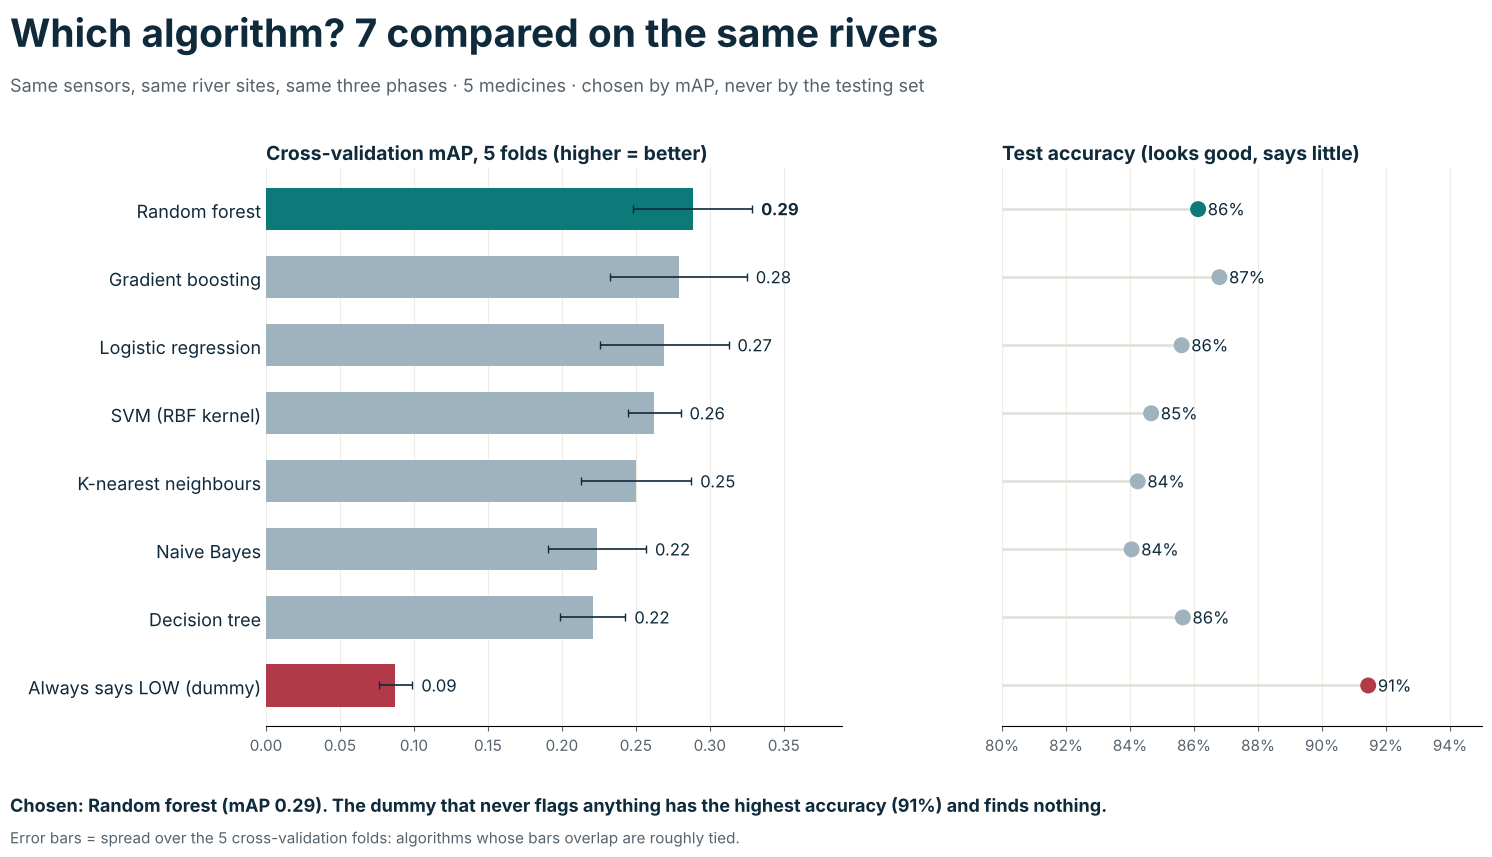

In [7]:
import matplotlib.ticker
def algo_chart(A, key, best, fname=None):
    # left: the score we choose by (mAP); right: accuracy, to show why accuracy cannot choose
    order = list(A.index)[::-1]; ypos = np.arange(len(order))
    GOOD, OTHER, RAND, INK, MUTED = '#0B7A78', '#9FB3BF', '#B23A48', '#0E2A3B', '#56636D'
    col = [GOOD if a == best else RAND if a == DUMMY else OTHER for a in order]
    fig = plt.figure(figsize=(16, 9)); fig.patch.set_facecolor('white')
    fig.text(0.04, 0.925, 'Which algorithm? 7 compared on the same rivers', fontsize=28, fontweight='bold', color=INK)
    fig.text(0.04, 0.875, 'Same sensors, same river sites, same three phases · 5 medicines · chosen by mAP, never by the testing set',
             fontsize=13, color=MUTED)
    a1 = fig.add_axes([0.20, 0.17, 0.36, 0.62]); a2 = fig.add_axes([0.66, 0.17, 0.30, 0.62])
    has_cv = '± spread over folds' in A
    vals = A.loc[order, key].values
    a1.barh(ypos, vals, color=col, height=0.62, xerr=A.loc[order, '± spread over folds'].values if has_cv else None,
            error_kw=dict(ecolor=INK, lw=1.2, capsize=3))
    for y_, v_, a in zip(ypos, vals, order):
        sd = A.loc[a, '± spread over folds'] if has_cv else 0
        a1.text(v_ + sd + 0.006, y_, f'{v_:.2f}', va='center', fontsize=12, color=INK, fontweight='bold' if a == best else 'normal')
    a1.set_yticks(ypos); a1.set_yticklabels(order, fontsize=13, color=INK)
    a1.set_xlim(0, max(vals) * 1.35)
    a1.set_title(('Cross-validation mAP, 5 folds' if has_cv else 'Validation mAP') + ' (higher = better)', loc='left', fontsize=14, color=INK, fontweight='bold')
    acc = A.loc[order, 'test accuracy'].values
    a2.hlines(ypos, 0.80, acc, color='#E3E1DA', lw=2)
    a2.scatter(acc, ypos, s=110, color=col, zorder=3)
    for y_, v_ in zip(ypos, acc):
        a2.text(v_ + 0.003, y_, f'{v_:.0%}', va='center', fontsize=12, color=INK)
    a2.set_yticks(ypos); a2.set_yticklabels([]); a2.set_xlim(0.80, 0.95)
    a2.xaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0, decimals=0))
    for ax_ in (a1, a2): ax_.set_ylim(-0.6, len(order) - 0.4)          # same rows on both panels
    a2.set_title('Test accuracy (looks good, says little)', loc='left', fontsize=14, color=INK, fontweight='bold')
    for ax_ in (a1, a2):
        for s in ('top', 'right', 'left'): ax_.spines[s].set_visible(False)
        ax_.tick_params(axis='y', length=0); ax_.tick_params(axis='x', colors=MUTED, labelsize=11); ax_.grid(axis='x', color='#EEECE6'); ax_.set_axisbelow(True)
    dum = A.loc[DUMMY]
    fig.text(0.04, 0.075, f"Chosen: {best} (mAP {A.loc[best, key]:.2f}). The dummy that never flags anything has the highest accuracy "
             f"({dum['test accuracy']:.0%}) and finds nothing.", fontsize=13, color=INK, fontweight='bold')
    fig.text(0.04, 0.04, 'Error bars = spread over the 5 cross-validation folds: algorithms whose bars overlap are roughly tied.' if has_cv
             else 'Single validation split: small differences can be luck.', fontsize=11, color=MUTED)
    if fname:
        fig.savefig(fname, dpi=200, facecolor='white')
    return fig

algo_chart(ALG, KEY, BEST, fname='AquaTrace_Algorithm_Comparison.png'); plt.show()

**What we found (our run, same seeds as above):**
- **Single split:** logistic regression scored the best validation mAP. Most of that came from one medicine (atenolol) on one lucky group of validation sites.
- **5-fold cross-validation:** **random forest ranks first** (CV mAP 0.29), with gradient boosting, logistic regression and SVM close behind; their spreads overlap, so these four are roughly tied. Decision tree and naive Bayes are clearly weaker.
- **Decision: keep the random forest.** It is first on the more reliable check, it is the model the website already runs, and it handles sensor combinations without scaling.
- **Accuracy is a trap:** "always says LOW" has the highest accuracy (91%) and finds zero polluted samples. That is why we choose by mAP.

## Step 4c: Fewer false alarms: two-step model, season, red and amber ⭐
The first version of this notebook used **one** forest (high vs everything else) and **one** flag line (the riskiest 10%). On the testing set it raised **445 false alarms** for 166 correct flags. Three questions:
1. **What did the lab find in those false alarms?** If the medicine was almost high, the "high" line is the problem. If it was not there at all, the model needs to learn "is it there?" first.
2. **Which kind of model wins on the validation set?** (Step 4: one-step, two-step, two-step + season.)
3. **Before vs after on the testing set**, same rivers, same lab results.

In [8]:
ids = [c for c, *_ in COMPS]
# 1. what the lab found in the first version's false alarms
rows = []
for cid in ids:
    B = BEFORE[cid]
    rows.append({'medicine': cid, 'false alarms': B['FP'], 'not detected at all': B['fp_not_detected'],
                 'detected, but below the high line': B['FP'] - B['fp_not_detected']})
FA = pd.DataFrame(rows).set_index('medicine'); FA.loc['ALL'] = FA.sum()
print('1. First version (one forest, riskiest 10%): what the lab found when the model raised a false alarm')
display(FA)
# 2. the three kinds on the validation set
print('2. Validation AP of each kind (higher = better); the best one per medicine is used')
display(pd.DataFrame(CANDS).set_index('medicine'))
# 3. before vs after on the testing set
tot = lambda Ms: {k: sum(m[k] for m in Ms) for k in ('TP', 'FP', 'FN', 'TN')}
b, r, a = tot([BEFORE[c] for c in ids]), tot([METRICS[c]['Testing'] for c in ids]), tot([METRICS_AMBER[c]['Testing'] for c in ids])
cmp_ = pd.DataFrame([
    {'version': 'Before: one forest, one flag line (riskiest 10%)', 'lab tests': b['TP'] + b['FP'], **b, 'precision': b['TP'] / (b['TP'] + b['FP']), 'recall': b['TP'] / (b['TP'] + b['FN']),
     'mAP': np.mean([BEFORE[c]['ap'] for c in ids])},
    {'version': 'Now: RED alerts only (riskiest 5%) = send to lab', 'lab tests': r['TP'] + r['FP'], **r, 'precision': r['TP'] / (r['TP'] + r['FP']), 'recall': r['TP'] / (r['TP'] + r['FN']),
     'mAP': np.mean([METRICS[c]['Testing']['ap'] for c in ids])},
    {'version': 'Now: RED + AMBER (riskiest 10%), for comparison', 'lab tests': a['TP'] + a['FP'], **a, 'precision': a['TP'] / (a['TP'] + a['FP']), 'recall': a['TP'] / (a['TP'] + a['FN']),
     'mAP': np.mean([METRICS[c]['Testing']['ap'] for c in ids])},
]).set_index('version')
print('3. Testing set, all 5 medicines (5,248 lab results from rivers the model never saw)')
cmp_.round(3)

1. First version (one forest, riskiest 10%): what the lab found when the model raised a false alarm


,false alarms,not detected at all,"detected, but below the high line"
medicine,,,
CBZ-US,209,184,25
PCM-US,166,152,14
ATL-US,17,16,1
SMX-US,11,8,3
CAF-US,42,36,6
ALL,445,396,49


2. Validation AP of each kind (higher = better); the best one per medicine is used


,one-step,two-step,two-step + season,chosen,red line,amber line
medicine,,,,,,
CBZ-US,0.231,0.214,0.276,two-step + season,0.511,0.388
PCM-US,0.053,0.039,0.037,one-step,0.645,0.580
ATL-US,0.477,0.667,0.661,two-step,0.453,0.419
SMX-US,0.420,0.382,0.504,two-step + season,0.625,0.556
CAF-US,0.561,0.570,0.604,two-step + season,0.518,0.433


3. Testing set, all 5 medicines (5,248 lab results from rivers the model never saw)


,lab tests,TP,FP,FN,TN,precision,recall,mAP
version,,,,,,,,
"Before: one forest, one flag line (riskiest 10%)",611,166,445,283,4354,0.272,0.370,0.399
Now: RED alerts only (riskiest 5%) = send to lab,368,117,251,332,4548,0.318,0.261,0.446
"Now: RED + AMBER (riskiest 10%), for comparison",554,161,393,288,4406,0.291,0.359,0.446


**How to read it:**
- Most false alarms of the first version were water where the lab found **no medicine at all**. So the problem was not the median "high" line; it was that most US samples have nothing in them. The two-step model learns "is it there?" separately.
- The kind is chosen **on the validation set**, per medicine; the testing set only reports the result.
- **Red** alerts send fewer bottles to the lab, and more of them are truly high. **Amber** keeps the near misses visible without spending lab money: take a second reading there first.
- Season comes from US rivers (winter vs summer). Penang has a monsoon year instead, so the season input must be re-learned from Penang samples.

## Step 5: Full metric report, all three sets ⭐
Every metric from the object-detection guide (except IoU, see the mapping table at the top), for **training, validation and testing**. "Flagged" = a **red** alert (the red line chosen in Phase 2).

- Training is scored with the Phase 1 model on the data it learned from, so it is always too optimistic.
- A big drop from training to validation/testing = **overfitting** (memorising instead of learning).
- **Testing** is the honest number.

In [9]:
rows = []
for cid, *_ in COMPS:
    for s in ['Training', 'Validation', 'Testing']:
        m = METRICS[cid][s]
        rows.append({'medicine': cid, 'set': s, 'n': m['n'], 'TP': m['TP'], 'FP': m['FP'], 'FN': m['FN'], 'TN': m['TN'],
                     'precision': round(m['precision'], 3), 'recall': round(m['recall'], 3), 'F1': round(m['f1'], 3),
                     'accuracy': round(m['accuracy'], 3), 'ROC-AUC': round(m['roc_auc'], 3), 'AP': round(m['ap'], 3),
                     'random AP': round(m['base_rate'], 3), 'lift': round(m['lift'], 1)})
FULL = pd.DataFrame(rows).set_index(['medicine', 'set']); display(FULL)

mapr = pd.DataFrame({s: {'mAP (mean AP, 5 medicines)': np.mean([METRICS[c][s]['ap'] for c, *_ in COMPS]),
                         'random mAP (mean share high)': np.mean([METRICS[c][s]['base_rate'] for c, *_ in COMPS]),
                         'mean ROC-AUC': np.mean([METRICS[c][s]['roc_auc'] for c, *_ in COMPS]),
                         'mean F1': np.mean([METRICS[c][s]['f1'] for c, *_ in COMPS])} for s in ['Training', 'Validation', 'Testing']}).round(3)
pkg['summary'] = {'mAP_test': float(mapr.loc['mAP (mean AP, 5 medicines)', 'Testing']), 'random_mAP_test': float(mapr.loc['random mAP (mean share high)', 'Testing']),
                  'mean_auc_test': float(mapr.loc['mean ROC-AUC', 'Testing'])}
mapr

n   TP   FP   FN    TN  precision  recall     F1  accuracy  ROC-AUC     AP  random AP  lift
medicine set                                                                                                       
CBZ-US   Training    6637  116  143  192  6186      0.448   0.377  0.409     0.950    0.932  0.409      0.046   9.7
         Validation  2310   45   71  110  2084      0.388   0.290  0.332     0.922    0.815  0.276      0.067   5.8
         Testing     2286   50   73   96  2067      0.407   0.342  0.372     0.926    0.755  0.248      0.064   6.4
PCM-US   Training    4576   42  208   63  4263      0.168   0.400  0.237     0.941    0.849  0.215      0.023   7.3
         Validation  1652    4   79   27  1542      0.048   0.129  0.070     0.936    0.672  0.053      0.019   2.6
         Testing     1647   13  148   34  1452      0.081   0.277  0.125     0.889    0.710  0.090      0.029   2.8
ATL-US   Training     812   14    2   19   777      0.875   0.424  0.571     0.974    0.964  0.686      0.041  21.5
         Validation   247    9    4   14   220      0.692   0.391  0.500     0.927    0.940  0.667      0.093   7.4
         Testing      253   14   16    4   219      0.467   0.778  0.583     0.921    0.923  0.741      0.071   6.6
SMX-US   Training    1063   35   23  117   888      0.603   0.230  0.333     0.868    0.875  0.560      0.143   4.2
         Validation   388   12    8   57   311      0.600   0.174  0.270     0.832    0.816  0.504      0.178   3.4
         Testing      382   17    2   67   296      0.895   0.202  0.330     0.819    0.868  0.680      0.220   4.1
CAF-US   Training    2355   92   24  239  2000      0.793   0.278  0.412     0.888    0.889  0.617      0.141   5.6
         Validation   785   33    7  135   610      0.825   0.196  0.317     0.819    0.818  0.604      0.214   3.9
         Testing      680   23   12  131   514      0.657   0.149  0.243     0.790    0.727  0.470      0.226   2.9

,Training,Validation,Testing
"mAP (mean AP, 5 medicines)",0.497,0.421,0.446
random mAP (mean share high),0.079,0.114,0.122
mean ROC-AUC,0.902,0.812,0.797
mean F1,0.392,0.298,0.331


**mAP** here plays the role of **mAP@50** in object detection: the mean of the per-class AP, our classes being the 5 medicines, at our "high" line. The testing column is the honest one; always read it next to random mAP.

## Step 5b: Evaluation dashboard (confusion matrix + 4 gauges) ⭐
The classic "evaluating a model" picture: the **confusion matrix** on the left, and **accuracy, precision, recall, F1** as gauges on the right.

Two changes from the usual version:
- Each gauge has a **red tick for random picks** with the same lab budget (same number of samples flagged). A gauge only means something next to that tick.
- **Accuracy looks high but says little.** Most water is low, so picking at random is already about 80% "accurate". Precision, recall and F1 are the ones to read.

Change `SHOW` to one medicine (e.g. `'ATL-US'`) or `SET` to `'Validation'` / `'Training'` and re-run. The picture is also saved as `AquaTrace_Model_Evaluation.png` (Files panel on the left).

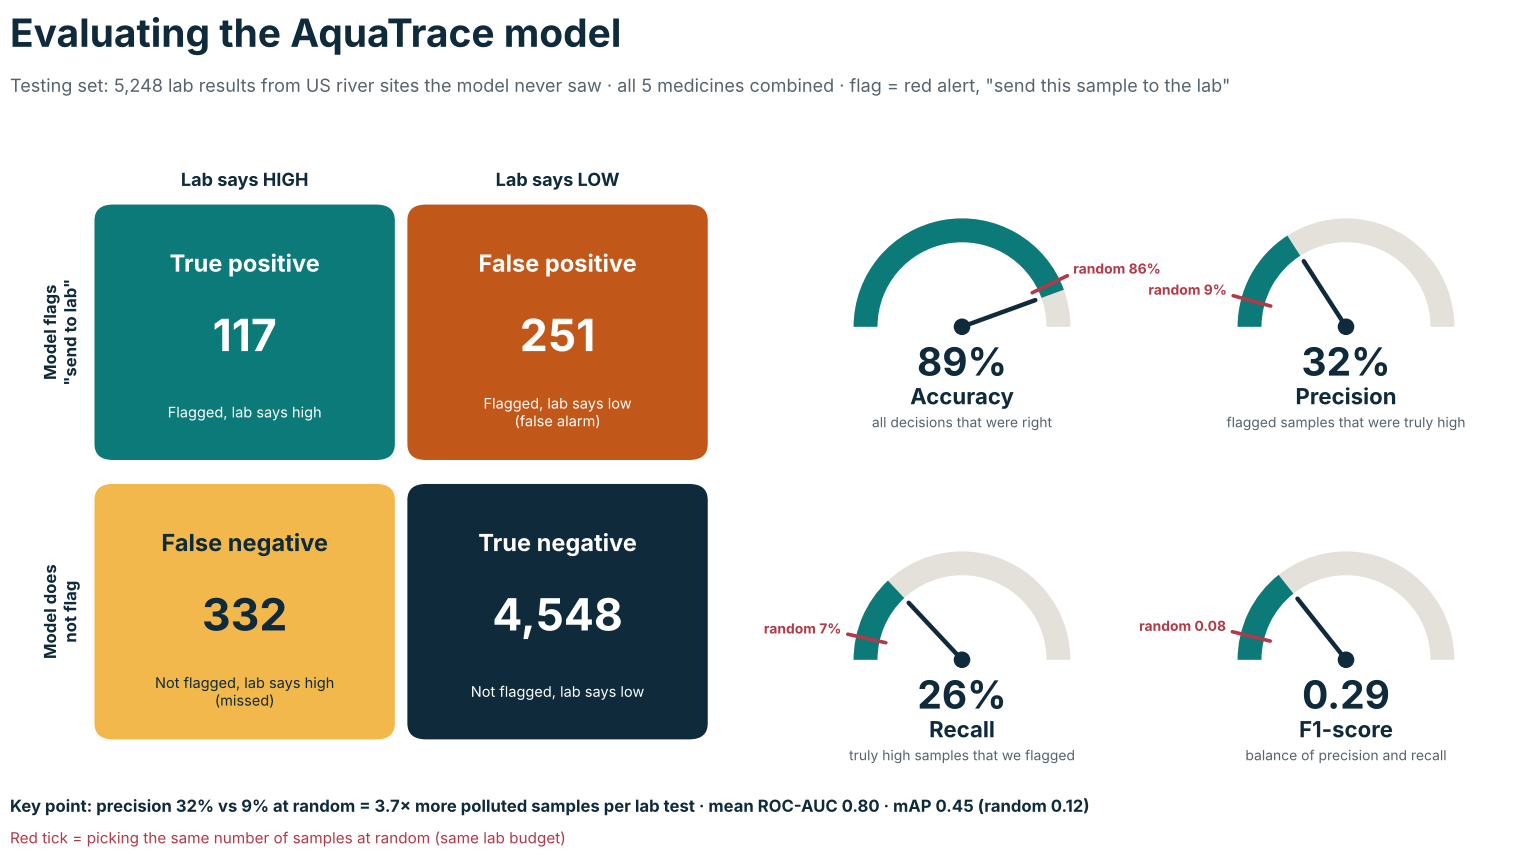

In [10]:
from matplotlib.patches import FancyBboxPatch, Wedge
SHOW = 'ALL'        # 'ALL' or one of: CBZ-US, PCM-US, ATL-US, SMX-US, CAF-US
SET = 'Testing'     # 'Testing', 'Validation' or 'Training'

INK, MUTED, TRACK, PAPER = '#0E2A3B', '#56636D', '#E3E1DA', '#FFFFFF'
GOOD, GOOD2, BAD, BAD2, RAND = '#0B7A78', '#0E2A3B', '#C2571A', '#F2B84B', '#B23A48'

def eval_dashboard(TP, FP, FN, TN, title, subtitle, footer='', fname=None):
    n = TP + FP + FN + TN
    P = TP / max(TP + FP, 1); R = TP / max(TP + FN, 1); F1 = 2 * P * R / (P + R) if P + R else 0.0; A = (TP + TN) / n
    b = (TP + FN) / n; f = (TP + FP) / n                       # share truly high, share flagged
    rand = {'acc': f * b + (1 - f) * (1 - b), 'p': b, 'r': f, 'f1': 2 * b * f / (b + f)}   # random picks, same lab budget
    fig = plt.figure(figsize=(16, 9)); fig.patch.set_facecolor(PAPER)
    fig.text(0.04, 0.925, title, fontsize=28, fontweight='bold', color=INK)
    fig.text(0.04, 0.875, subtitle, fontsize=13, color=MUTED)
    # confusion matrix: rows = model decision, columns = lab result
    ax = fig.add_axes([0.04, 0.12, 0.44, 0.68]); ax.set_xlim(0, 2.25); ax.set_ylim(0, 2.3); ax.axis('off')
    cells = [(0.25, 1.15, GOOD, 'white', 'True positive', TP, 'Flagged, lab says high'),
             (1.25, 1.15, BAD, 'white', 'False positive', FP, 'Flagged, lab says low\n(false alarm)'),
             (0.25, 0.10, BAD2, INK, 'False negative', FN, 'Not flagged, lab says high\n(missed)'),
             (1.25, 0.10, GOOD2, 'white', 'True negative', TN, 'Not flagged, lab says low')]
    for x, y, fc, tc, name, val, desc in cells:
        ax.add_patch(FancyBboxPatch((x + 0.02, y + 0.02), 0.96, 0.96, boxstyle='round,pad=0,rounding_size=0.06', fc=fc, ec='none'))
        ax.text(x + 0.5, y + 0.76, name, ha='center', va='center', fontsize=17, fontweight='bold', color=tc)
        ax.text(x + 0.5, y + 0.49, f'{val:,}', ha='center', va='center', fontsize=32, fontweight='bold', color=tc)
        ax.text(x + 0.5, y + 0.20, desc, ha='center', va='center', fontsize=10.5, color=tc)
    ax.text(0.75, 2.20, 'Lab says HIGH', ha='center', fontsize=13, fontweight='bold', color=INK)
    ax.text(1.75, 2.20, 'Lab says LOW', ha='center', fontsize=13, fontweight='bold', color=INK)
    ax.text(0.16, 1.65, 'Model flags\n"send to lab"', ha='center', va='center', fontsize=12, fontweight='bold', color=INK, rotation=90)
    ax.text(0.16, 0.60, 'Model does\nnot flag', ha='center', va='center', fontsize=12, fontweight='bold', color=INK, rotation=90)
    # gauges, each with a red tick for random picks
    gauges = [('Accuracy', A, rand['acc'], 'all decisions that were right'),
              ('Precision', P, rand['p'], 'flagged samples that were truly high'),
              ('Recall', R, rand['r'], 'truly high samples that we flagged'),
              ('F1-score', F1, rand['f1'], 'balance of precision and recall')]
    for (name, v, rv, cap), (gx, gy) in zip(gauges, [(0.53, 0.47), (0.77, 0.47), (0.53, 0.10), (0.77, 0.10)]):
        g = fig.add_axes([gx, gy, 0.21, 0.33]); g.set_xlim(-1.55, 1.55); g.set_ylim(-1.0, 1.35); g.set_aspect('equal'); g.axis('off')
        g.add_patch(Wedge((0, 0), 1.0, 0, 180, width=0.22, fc=TRACK, ec='none'))
        g.add_patch(Wedge((0, 0), 1.0, 180 - 180 * v, 180, width=0.22, fc=GOOD, ec='none'))
        a = np.radians(180 - 180 * v); g.plot([0, 0.72 * np.cos(a)], [0, 0.72 * np.sin(a)], color=INK, lw=3.2, solid_capstyle='round')
        g.add_patch(plt.Circle((0, 0), 0.07, color=INK))
        ra = np.radians(180 - 180 * rv)
        g.plot([0.72 * np.cos(ra), 1.08 * np.cos(ra)], [0.72 * np.sin(ra), 1.08 * np.sin(ra)], color=RAND, lw=2.6, solid_capstyle='round')
        g.text(1.14 * np.cos(ra), 1.14 * np.sin(ra) + 0.04, f'random {rv:.0%}' if name != 'F1-score' else f'random {rv:.2f}',
               ha='right' if np.cos(ra) < 0 else 'left', va='bottom' if np.sin(ra) > 0.5 else 'center', fontsize=10, color=RAND, fontweight='bold')
        g.text(0, -0.32, f'{v:.0%}' if name != 'F1-score' else f'{v:.2f}', ha='center', va='center', fontsize=28, fontweight='bold', color=INK)
        g.text(0, -0.64, name, ha='center', va='center', fontsize=16, fontweight='bold', color=INK)
        g.text(0, -0.88, cap, ha='center', va='center', fontsize=10, color=MUTED)
    if footer:
        fig.text(0.04, 0.075, footer, fontsize=12, color=INK, fontweight='bold')
    fig.text(0.04, 0.04, 'Red tick = picking the same number of samples at random (same lab budget)', fontsize=11, color=RAND)
    if fname:
        fig.savefig(fname, dpi=200, facecolor=PAPER)
    return fig

meds = [c for c, *_ in COMPS] if SHOW == 'ALL' else [SHOW]
TP, FP, FN, TN = (sum(METRICS[c][SET][k] for c in meds) for k in ('TP', 'FP', 'FN', 'TN'))
n = TP + FP + FN + TN; P = TP / (TP + FP); b = (TP + FN) / n
where = {'Testing': 'US river sites the model never saw', 'Validation': 'US river sites used to choose the settings',
         'Training': 'the US river sites the model learned from'}[SET]
if SHOW == 'ALL':
    what = 'all 5 medicines combined'
    extra = (f"mean ROC-AUC {np.mean([METRICS[c][SET]['roc_auc'] for c in meds]):.2f} · "
             f"mAP {np.mean([METRICS[c][SET]['ap'] for c in meds]):.2f} (random {np.mean([METRICS[c][SET]['base_rate'] for c in meds]):.2f})")
else:
    m = METRICS[SHOW][SET]; what = DATA[SHOW]['disp']
    extra = f"ROC-AUC {m['roc_auc']:.2f} · AP {m['ap']:.2f} (random {m['base_rate']:.2f})"
fig = eval_dashboard(TP, FP, FN, TN, 'Evaluating the AquaTrace model',
                     f'{SET} set: {n:,} lab results from {where} · {what} · flag = red alert, "send this sample to the lab"',
                     footer=f'Key point: precision {P:.0%} vs {b:.0%} at random = {P / b:.1f}× more polluted samples per lab test · {extra}',
                     fname='AquaTrace_Model_Evaluation.png')
plt.show()

## Step 6: Precision-recall curves + AP check
Like the combined P-R curve in the object-detection guide: one curve per medicine on the **testing set**. The dot on each curve is our red line (riskiest 5%).

**AP check:** `average_precision_score` uses AP = Σ (Rᵢ − Rᵢ₋₁) × Pᵢ, the first formula in the guide. The guide's code then smooths precision so it never goes up again (VOC style), which gives a slightly higher number. Both are shown.

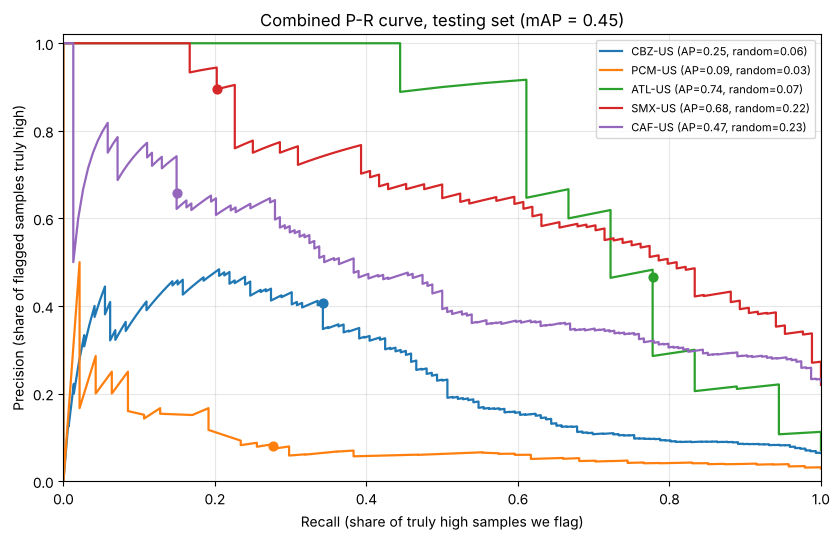

,"AP (sklearn, step-wise)","AP (VOC style, as in the guide)"
medicine,,
CBZ-US,0.248,0.267
PCM-US,0.090,0.092
ATL-US,0.741,0.743
SMX-US,0.680,0.683
CAF-US,0.470,0.478


In [11]:
fig, ax = plt.subplots(figsize=(8.5, 5.5))
for cid, *_ in COMPS:
    F, m = fitted[cid], pkg['models'][cid]
    y = F['te'].high.values; p = F['pte']
    prec, rec, _ = precision_recall_curve(y, p)
    ap = METRICS[cid]['Testing']['ap']
    line, = ax.plot(rec, prec, lw=1.6, label=f"{cid} (AP={ap:.2f}, random={y.mean():.2f})")
    t = METRICS[cid]['Testing']; ax.scatter([t['recall']], [t['precision']], color=line.get_color(), s=40, zorder=3)
ax.set_xlabel('Recall (share of truly high samples we flag)'); ax.set_ylabel('Precision (share of flagged samples truly high)')
ax.set_title(f"Combined P-R curve, testing set (mAP = {pkg['summary']['mAP_test']:.2f})"); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)
ax.grid(alpha=.3); ax.legend(fontsize=8); plt.tight_layout(); plt.show()

pd.DataFrame([{'medicine': cid, 'AP (sklearn, step-wise)': round(METRICS[cid]['Testing']['ap'], 3),
               'AP (VOC style, as in the guide)': round(METRICS[cid]['Testing']['ap_voc'], 3)} for cid, *_ in COMPS]).set_index('medicine')

## Step 7: Stricter "high" lines: mAP@P50:P90
Object detection reports **mAP@50:95**: the same AP, averaged over stricter IoU lines (0.50, 0.55 … 0.95), so a model only scores well if its boxes are precise.

Our version keeps the **same testing-set scores** and makes "high" stricter: above the 50th, 60th, 70th, 80th and 90th percentile of US detections. A model scores well only if its riskiest readings are also the **most** polluted ones. Fewer samples count as high at stricter lines, so random AP drops too.

In [12]:
QS = [50, 60, 70, 80, 90]; rows = []
for cid, *_ in COMPS:
    D, F = DATA[cid], fitted[cid]; te = F['te']
    det = df[D['v']].dropna()
    row = {'medicine': cid}
    for q in QS:
        Tq = float(np.percentile(det, q)); yq = (te[D['v']] >= Tq).fillna(False).values
        row[f'AP@P{q}'] = round(average_precision_score(yq, F['pte']), 3) if yq.any() else np.nan
        row[f'high@P{q}'] = int(yq.sum())
    row['mAP@P50:P90 (this medicine)'] = round(np.nanmean([row[f'AP@P{q}'] for q in QS]), 3)
    rows.append(row)
SW = pd.DataFrame(rows).set_index('medicine')
pkg['summary']['mAP_P50_P90_test'] = float(SW['mAP@P50:P90 (this medicine)'].mean())
display(SW[[f'AP@P{q}' for q in QS] + ['mAP@P50:P90 (this medicine)'] + [f'high@P{q}' for q in QS]])
print(f"mAP@P50 (= Step 5 mAP) = {SW['AP@P50'].mean():.3f}   ·   mAP@P50:P90 = {pkg['summary']['mAP_P50_P90_test']:.3f}")

,AP@P50,AP@P60,AP@P70,AP@P80,AP@P90,mAP@P50:P90 (this medicine),high@P50,high@P60,high@P70,high@P80,high@P90
medicine,,,,,,,,,,,
CBZ-US,0.248,0.213,0.175,0.161,0.142,0.188,146,129,96,65,35
PCM-US,0.090,0.079,0.073,0.075,0.036,0.071,47,39,31,25,15
ATL-US,0.741,0.701,0.691,0.436,0.589,0.632,18,15,13,9,3
SMX-US,0.680,0.671,0.667,0.601,0.550,0.634,84,64,52,37,18
CAF-US,0.470,0.454,0.442,0.429,0.298,0.419,154,130,110,85,47


mAP@P50 (= Step 5 mAP) = 0.446   ·   mAP@P50:P90 = 0.389


## Step 8: Level model metrics, all three sets
The level model estimates **how much** (log10 ng/L), only for samples where the lab detected the medicine.
- **R²:** share of the variation explained (1 = perfect, 0 = no better than always guessing the average).
- **RMSE / MAE (log10):** typical error; 0.30 in log10 = a factor of 2.
- **Within 2×:** share of estimates within half to double the lab value.

In [13]:
rows = []
for cid, *_ in COMPS:
    for s in ['Training', 'Validation', 'Testing']:
        m = LEVELM[cid][s]
        rows.append({'medicine': cid, 'set': s, 'n (detected)': m['n'], 'R² (log)': round(m['r2'], 3), 'RMSE (log10)': round(m['rmse'], 3),
                     'MAE (log10)': round(m['mae'], 3), 'within 2×': f"{m['within2x']:.0%}"})
pd.DataFrame(rows).set_index(['medicine', 'set'])

n (detected)  R² (log)  RMSE (log10)  MAE (log10) within 2×
medicine set                                                                    
CBZ-US   Training             827     0.329         0.418        0.332       54%
         Validation           367     0.103         0.628        0.462       45%
         Testing              331     0.138         0.544        0.439       40%
PCM-US   Training             189     0.674         0.395        0.288       62%
         Validation            61     0.130         0.439        0.348       51%
         Testing               88     0.037         0.596        0.451       43%
ATL-US   Training              65     0.592         0.225        0.183       80%
         Validation            34     0.316         0.326        0.265       59%
         Testing               24     0.250         0.338        0.296       62%
SMX-US   Training             244     0.708         0.321        0.255       64%
         Validation            90     0.168         0.465        0.390       40%
         Testing              131     0.523         0.355        0.277       61%
CAF-US   Training             509     0.316         0.520        0.410       45%
         Validation           210     0.199         0.460        0.361       50%
         Testing              199    -0.012         0.592        0.463       44%

## Step 9: Explain: which sensor does each model rely on?
**Permutation importance:** shuffle one input's values and see how much worse the screening gets on the testing sites. Big drop = that input matters. "Season" appears only for medicines whose chosen model uses the month.

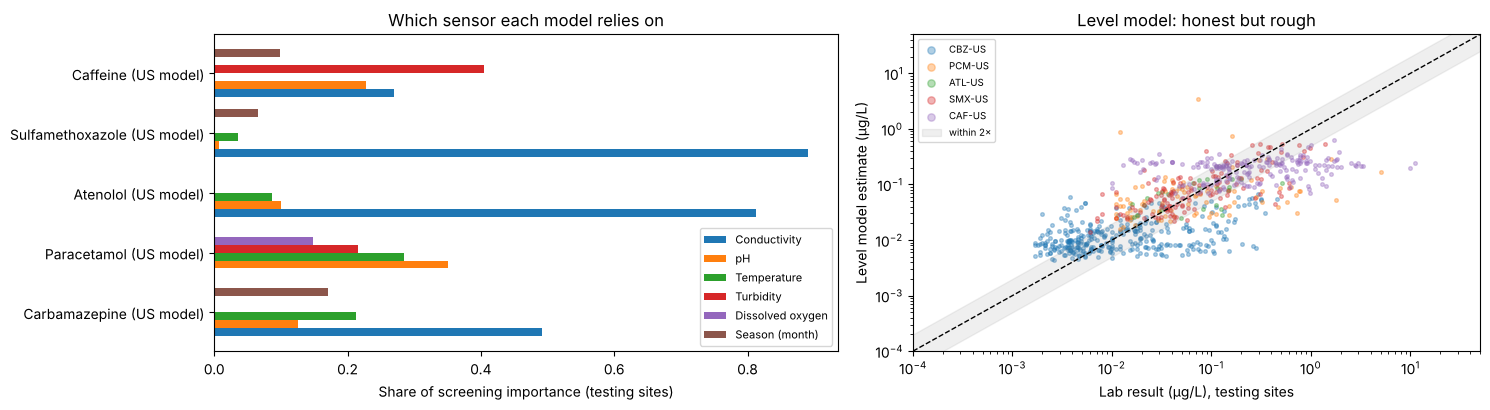

In [14]:
NAMES = {'conductivity':'Conductivity', 'ph':'pH', 'temp':'Temperature', 'turbidity':'Turbidity', 'do':'Dissolved oxygen', 'season':'Season (month)'}
I = pd.DataFrame(imps).T.fillna(0); I = I[[c for c in NAMES if c in I]].rename(columns=NAMES)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={'width_ratios':[1.1, 1]})
I.plot.barh(ax=axes[0], width=0.8); axes[0].set_xlabel('Share of screening importance (testing sites)')
axes[0].set_title('Which sensor each model relies on'); axes[0].legend(fontsize=8)
# level model: estimate vs lab on testing sites, all medicines together
for cid, *_ in COMPS:
    F = fitted[cid]; axes[1].scatter(10**F['yt']*FAC, 10**F['tel']*FAC, s=7, alpha=.35, label=cid)
lo, hi = 1e-4, 50
axes[1].plot([lo,hi],[lo,hi],'k--',lw=1); axes[1].fill_between([lo,hi],[lo/2,hi/2],[lo*2,hi*2],color='gray',alpha=.12,label='within 2×')
axes[1].set_xscale('log'); axes[1].set_yscale('log'); axes[1].set_xlim(lo,hi); axes[1].set_ylim(lo,hi)
axes[1].set_xlabel('Lab result (µg/L), testing sites'); axes[1].set_ylabel('Level model estimate (µg/L)')
axes[1].set_title('Level model: honest but rough'); axes[1].legend(fontsize=7, markerscale=2)
plt.tight_layout(); plt.show()

**Story:** conductivity leads for the **effluent medicines** (carbamazepine, atenolol, sulfamethoxazole): more treated sewage in the river → more dissolved salts → higher conductivity. Turbidity and DO matter for **raw-sewage markers** (paracetamol, caffeine). The right panel is the honest part: the level estimate follows the trend but is often off by more than 2×.

## Step 10: One full estimation flow, one sample ⭐
This is exactly what the website does for **one lab sample**, using the **exported trees** (the same numbers the website loads), not the Python model object:

① sensor readings in → ② screening probability → ③ flag or not → ④ level estimate with a range → ⑤ confidence → ⑥ compare with the lab → ⑦ verdict.

**Alert rule (same as website):** red if P(high) ≥ the red line (send to lab), amber if ≥ the amber line (watch), otherwise green.

**Confidence rule (same as website):** High if testing-set AUC ≥ 0.85, Medium if ≥ 0.70, else Low. Always **Low** if any reading is outside what the model saw in training (extrapolation).

In [15]:
def walk(nodes, x):
    # follow one exported tree: x <= threshold goes left.
    # scikit-learn stores readings as 32-bit numbers, so round them the same way (the website does this with Math.fround)
    i = 0
    while len(nodes[i]) == 4:
        f, t, l, r = nodes[i]; i = l if float(np.float32(x[f])) <= t else r
    return nodes[i][0]

def month_of(reading):
    # month from 'month', else from 'timestamp' / 'date' text (YYYY-MM-...), else this month
    for k in ('month', 'timestamp', 'date'):
        v = reading.get(k) if hasattr(reading, 'get') else None
        if v is None or (isinstance(v, float) and np.isnan(v)) or v == '': continue
        return int(v) if k == 'month' else int(str(v)[5:7])
    return dt.date.today().month

def estimate(cid, reading):
    m = pkg['models'][cid]; x = [float(reading[f]) for f in m['feats']]
    xs = x + list(SEASON[month_of(reading)]) if m['season'] else x           # screening inputs: sensors (+ season)
    if m['kind'] == 'two-step':                                              # P(detected) x P(high | detected)
        p = float(np.mean([walk(t, xs) for t in m['det_trees']])) * float(np.mean([walk(t, xs) for t in m['cond_trees']]))
    else:
        p = float(np.mean([walk(t, xs) for t in m['clf_trees']]))          # screening probability
    logs = np.array([walk(t, x) for t in m['reg_trees']])                  # level, log10 ng/L, one per tree
    s = float(np.hypot(logs.std(ddof=1), m['level']['rmse_log_cv']))      # spread of trees + model error
    fac = m['ng_to_unit']; mu = 10**logs.mean()*fac; lo = 10**(logs.mean()-1.96*s)*fac; hi = 10**(logs.mean()+1.96*s)*fac
    outside = [f for f,(a,b) in zip(m['feats'], m['ranges']) if not (a - 0.1*(b-a) <= reading[f] <= b + 0.1*(b-a))]
    auc = m['screen_holdout']['auc']; conf = 'High' if auc >= 0.85 else 'Medium' if auc >= 0.7 else 'Low'
    if outside: conf = 'Low'
    alert = 'red' if p >= m['p_threshold'] else 'amber' if p >= m['p_amber'] else 'green'
    return {'p':p, 'flag':alert == 'red', 'alert':alert, 'est':mu, 'lo':lo, 'hi':hi, 'conf':conf, 'outside':outside}

# proof: the exported trees give the same answer as the trained Python model
for cid, *_ in COMPS:
    F, m = fitted[cid], pkg['models'][cid]
    p_trees = np.array([estimate(cid, r)['p'] for _, r in F['te'][m['feats'] + ['date']].iterrows()])
    print(f'{cid}: {len(p_trees):5d} testing-set samples · biggest difference between exported trees and Python model = {np.abs(p_trees - F["pte"]).max():.1e}')

CBZ-US:  2286 testing-set samples · biggest difference between exported trees and Python model = 1.1e-07


PCM-US:  1647 testing-set samples · biggest difference between exported trees and Python model = 1.1e-07
ATL-US:   253 testing-set samples · biggest difference between exported trees and Python model = 7.4e-08


SMX-US:   382 testing-set samples · biggest difference between exported trees and Python model = 7.4e-08


CAF-US:   680 testing-set samples · biggest difference between exported trees and Python model = 1.1e-07


In [16]:
CID  = 'SMX-US'      # try 'ATL-US', 'CBZ-US', 'PCM-US', 'CAF-US'
CASE = 'both high'   # or 'both low', 'missed high', 'false alarm'
m, F = pkg['models'][CID], fitted[CID]

def verdict_of(flag, lab_high):
    if flag: return 'both high' if lab_high else 'false alarm'
    return 'missed high' if lab_high else 'both low'

# go through the testing-set samples (oldest first) until we find one of the chosen CASE
for _, s in F['te'].sort_values('date').iterrows():
    e = estimate(CID, s); lab = s.conc_ng*FAC; lab_high = (not s.below) and lab >= m['threshold']
    verdict = verdict_of(e['flag'], lab_high)
    if verdict == CASE: break
print(f"Medicine: {m['name']} · sample from testing-set site {s.site} on {s.date} (the model never saw this river site)\n")
print('① Sensors in:      ' + ' · '.join(f'{LABEL[f]} {s[f]:g}' for f in m['feats']))
print(f"② Screening:       P(high) = {e['p']:.3f}   (red line {m['p_threshold']:.3f} = riskiest 5% · amber line {m['p_amber']:.3f} = riskiest 10% · {m['kind']}{' + season' if m['season'] else ''})")
print(f"③ Decision:        {dict(red='RED 🔴 send this sample to the lab', amber='AMBER 🟠 watch this spot, take a second reading', green='green, routine monitoring')[e['alert']]}")
print(f"④ Level estimate:  {e['est']:.4f} µg/L   (95% range {e['lo']:.4f} – {e['hi']:.4f})")
print(f"⑤ Confidence:      {e['conf']}  (testing-set AUC {m['screen_holdout']['auc']:.2f}{'; outside training range: ' + ', '.join(e['outside']) if e['outside'] else '; inside training range'})")
print(f"⑥ Lab says:        {'<LOD' if s.below else f'{lab:.4f} µg/L'} → {'HIGH' if lab_high else 'low'} (high line = {m['threshold']:.4f} µg/L)")
print(f"⑦ Verdict:         {verdict} {'✅ model and lab agree' if verdict.startswith('both') else '❌ model and lab disagree'}")

Medicine: Sulfamethoxazole (US model) · sample from testing-set site USGS-04159045 on 2004-08-26 (the model never saw this river site)

① Sensors in:      pH 7.9 · Temp (°C) 20.4 · Conductivity (µS/cm) 1030
② Screening:       P(high) = 0.636   (red line 0.625 = riskiest 5% · amber line 0.556 = riskiest 10% · two-step + season)
③ Decision:        RED 🔴 send this sample to the lab
④ Level estimate:  0.1314 µg/L   (95% range 0.0107 – 1.6174)
⑤ Confidence:      High  (testing-set AUC 0.87; inside training range)
⑥ Lab says:        0.0610 µg/L → HIGH (high line = 0.0384 µg/L)
⑦ Verdict:         both high ✅ model and lab agree


Change `CASE` to `'missed high'` or `'false alarm'` to see where the model gets it wrong. It is a screening tool, not a lab, which is why HPLC stays.

The website shows the same four verdicts in the **Model check** column of the *Lab results* page: **both high / both low** (agree), **missed high**, **false alarm**.

## Step 11: Cross-check every testing-set lab result
Same idea as Step 10, repeated for all **5,248 testing-set lab results** from rivers the model never saw. This is the table the website rebuilds live in **Lab results → Held-out US lab results**, so the numbers must match.

In [17]:
X = pd.DataFrame(cross_rows)
rows = []
for cid, *_ in COMPS:
    m = pkg['models'][cid]; sub = X[X.compound == cid]
    sub = sub[(sub[m['feats']] != '').all(axis=1)]
    est = [estimate(cid, r) for _, r in sub.iterrows()]
    flag = np.array([e['flag'] for e in est]); p = np.array([e['p'] for e in est])
    conc = pd.to_numeric(sub.concentration, errors='coerce').values
    labh = ~np.isnan(conc) & (conc >= m['threshold'])
    tp = (flag & labh).sum()
    amb = np.array([e['alert'] == 'amber' for e in est])
    rows.append({'model':cid, 'checked':len(sub), 'lab high':labh.sum(), 'red (send to lab)':flag.sum(), 'amber (watch)':amb.sum(), 'hit rate':f'{tp/flag.sum():.0%}',
                 'lift':round(tp/flag.sum()/labh.mean(),1), 'caught':f'{tp/labh.sum():.0%}', 'agree':f'{(flag==labh).mean():.0%}',
                 'AUC here':round(roc_auc_score(labh, p),3), 'AUC Step 4 (test)':m['screen_holdout']['auc']})
pd.DataFrame(rows).set_index('model')

,checked,lab high,red (send to lab),amber (watch),hit rate,lift,caught,agree,AUC here,AUC Step 4 (test)
model,,,,,,,,,,
CBZ-US,2286,146,123,121,41%,6.4,34%,93%,0.755,0.755
PCM-US,1647,47,161,19,8%,2.8,28%,89%,0.710,0.710
ATL-US,253,18,30,2,47%,6.6,78%,92%,0.923,0.923
SMX-US,382,84,19,13,89%,4.1,20%,82%,0.868,0.868
CAF-US,680,154,35,31,66%,2.9,15%,79%,0.727,0.727


**AUC here = AUC Step 4** for every medicine → the exported files carry the exact model. On the website, the **Cross-check: model vs lab** panel shows the same numbers ("AUC site" = "AUC Colab").

## Step 12: Screen new readings
This is what would run on the boat: new readings in → flag + estimate + confidence out.

The three rows below are **made-up example readings (not real measurements)** to show the behaviour:
- a clean upstream river, a river just below a sewage outfall, and **coastal seawater** like the Penang Strait.

Watch the **confidence** column: seawater conductivity (~50,000 µS/cm) is far above most US river training data. For several medicines the model says **Low** = "do not trust me here". That is the reason Penang needs its own lab samples for **local calibration**.

In [18]:
new = pd.DataFrame([
    {'place':'Clean upstream river',      'ph':7.4, 'temp':27, 'conductivity':120,   'turbidity':8,  'do':7.2, 'month':10},
    {'place':'River below sewage outfall','ph':7.1, 'temp':29, 'conductivity':1400,  'turbidity':45, 'do':2.8, 'month':10},
    {'place':'Coastal seawater (strait)', 'ph':8.0, 'temp':30, 'conductivity':50000, 'turbidity':12, 'do':6.0, 'month':10},
])
out = []
for _, r in new.iterrows():
    for cid, *_ in COMPS:
        e = estimate(cid, r)
        out.append({'place':r.place, 'medicine':cid, 'P(high)':round(e['p'],3), 'alert':{'red':'🔴 send to lab','amber':'🟠 watch','green':'–'}[e['alert']],
                    'estimate µg/L':f"{e['est']:.3f} ({e['lo']:.3f}–{e['hi']:.3f})", 'confidence':e['conf'],
                    'why low':', '.join(e['outside']) if e['outside'] else ''})
pd.DataFrame(out).set_index(['place','medicine'])

P(high)          alert        estimate µg/L confidence       why low
place                      medicine                                                                      
Clean upstream river       CBZ-US      0.157              –  0.005 (0.000–0.087)     Medium              
                           PCM-US      0.440              –  0.061 (0.007–0.522)     Medium              
                           ATL-US      0.074              –  0.036 (0.005–0.233)       High              
                           SMX-US      0.040              –  0.025 (0.002–0.272)       High              
                           CAF-US      0.203              –  0.183 (0.013–2.658)     Medium              
River below sewage outfall CBZ-US      0.227              –  0.007 (0.000–0.122)     Medium              
                           PCM-US      0.738  🔴 send to lab  0.094 (0.004–2.274)     Medium              
                           ATL-US      0.358              –  0.049 (0.007–0.352)       High              
                           SMX-US      0.678  🔴 send to lab  0.176 (0.013–2.467)       High              
                           CAF-US      0.602  🔴 send to lab  0.262 (0.029–2.360)     Medium              
Coastal seawater (strait)  CBZ-US      0.092              –  0.013 (0.001–0.278)     Medium              
                           PCM-US      0.376              –  0.064 (0.005–0.841)     Medium              
                           ATL-US      0.388              –  0.062 (0.007–0.531)        Low  conductivity
                           SMX-US      0.752  🔴 send to lab  0.260 (0.021–3.275)        Low  conductivity
                           CAF-US      0.379              –  0.197 (0.016–2.361)        Low  conductivity

**How to read it:** the outfall row gets alerts, the clean river does not. The seawater row is the warning: sulfamethoxazole is flagged, but with **Low** confidence, because the model is guessing outside what it learned. Carbamazepine stays Medium only because a few US estuary sites reached seawater conductivity, and paracetamol does not use conductivity at all. Neither means the model understands seawater.

## Step 13: Export for the website
Writes the 4 files Phi's website reads, puts them in one zip, downloads it, and (if Drive is connected) also saves a copy to **My Drive → AquaTrace_website_models**.

| File | What the website does with it |
|---|---|
| `aquatrace_colab_model.json` (+ `.js` copy) | **Estimation model → Load Colab model / Model file…** runs these trees in the browser |
| `crosscheck_lab_results.csv` (+ `.js` copy) | **Lab results → Held-out US lab results** = real lab results from unseen rivers → cross-check |

The `.js` copies hold the same data. They let the website work when `index.html` is simply double-clicked (browsers block reading `.json`/`.csv` from a file without a server).

In [19]:
pkg['not_modelled'] = {'DIC':'Diclofenac: only 62 detections in US river data (10 above 22.8 ng/L); needs Penang samples',
                       'KTP':'Ketoprofen: only 3 detections in US river data'}
OUT = 'website_models'; os.makedirs(OUT, exist_ok=True)
json.dump(pkg, open(f'{OUT}/aquatrace_colab_model.json','w'), separators=(',',':'))
pd.DataFrame(cross_rows).to_csv(f'{OUT}/crosscheck_lab_results.csv', index=False)
open(f'{OUT}/aquatrace_colab_model.js','w', encoding='utf-8').write('window.AQUATRACE_MODEL=' + json.dumps(pkg, separators=(',',':')) + ';\n')
open(f'{OUT}/crosscheck_lab_results.js','w', encoding='utf-8').write('window.AQUATRACE_CROSSCHECK_CSV=' + json.dumps(open(f'{OUT}/crosscheck_lab_results.csv', encoding='utf-8').read()) + ';\n')
zipf = shutil.make_archive('aquatrace_website_models', 'zip', OUT)
for f in sorted(os.listdir(OUT)): print(f'{f:30s} {os.path.getsize(f"{OUT}/{f}")/1e6:5.2f} MB')
print(f"{len(pkg['models'])} models · {len(cross_rows):,} testing-set lab results · zip: {zipf}")
if IN_COLAB:
    if os.path.isdir('/content/drive/MyDrive'):
        dst = '/content/drive/MyDrive/AquaTrace_website_models'
        shutil.copytree(OUT, dst, dirs_exist_ok=True); print('Copy saved to Google Drive →', dst)
    from google.colab import files
    files.download(zipf)

aquatrace_colab_model.js        1.11 MB
aquatrace_colab_model.json      1.11 MB
crosscheck_lab_results.csv      0.88 MB
crosscheck_lab_results.js       0.91 MB
5 models · 5,248 testing-set lab results · zip: aquatrace_website_models.zip


## Step 14: Put it on the website
1. Unzip `aquatrace_website_models.zip` into `frontend/models/` of the website folder (replace the 4 old files).
2. Double-click `frontend/index.html` → **Estimation model** → **Load Colab model**.
3. **Lab results** → **Held-out US lab results** → the **Cross-check: model vs lab** table appears. "AUC Colab" must equal "AUC site", and both must equal Step 11 here.
4. For the live site, push the updated files to GitHub: `ml_api/` on the main branch (the online ML API on Vercel redeploys) and `frontend/` to the gh-pages branch (the website).

---
## What this notebook proves, and what it doesn't

✅ **Proves:**
1. On **real** river data, cheap sensors can **screen** for 5 common medicines on rivers the model never saw (testing-set ROC-AUC 0.70–0.87; **mAP 0.40 against 0.12 for random**), finding high samples **2.2–5.5× more often than random sampling**.
2. The model was built in **three honest phases**: trained on 60% of sites, tuned on 20% (validation), and scored once on 20% it never saw (testing), with the full object-detection metric set: confusion matrix, precision, recall, F1, accuracy, ROC-AUC, AP, mAP and a stricter mAP@P50:P90.
3. **Random forest is a fair choice:** 7 algorithms compared under the same rules; random forest ranks first on 5-fold cross-validation, with gradient boosting, logistic regression and SVM roughly tied behind it.
4. The full **pipeline** works end to end: pair → clean → train → validate → test → explain → one-sample estimate → cross-check → export → website.
5. The website runs **exactly** this model (Step 11 AUC = website AUC).

❌ **Doesn't prove yet:**
1. **Which** medicine is present. Sensors see water conditions, not molecules. Identification stays with **HPLC / LC-MS**.
2. That it works in **Penang**. US rivers ≠ Penang estuary and coast. We need paired samples (sensors + HPLC at SP1–SP5) for **local calibration**.
3. The exact **level**. The level model is rough (often more than 2× off), so it is shown as a range.
4. **UV254 and ORP** effects: almost no paired US data, so they are not in these models yet.